### Top

In [1]:
from volta.prelude import *
np.set_printoptions(precision=4, suppress=True)

In [2]:
meshcat = StartMeshcat()
port = str(meshcat.web_url())[-4:]
# print(f"Sharing URL: tanawatp@tanawatp-ROG-Strix.local:{port}")
print(f"Sharing URL: fibo4@fibo4.local:{port}")
print(f"Download URL: {meshcat.web_url()}/download")

INFO:drake:Meshcat listening for connections at http://localhost:7001


Sharing URL: fibo4@fibo4.local:7001
Download URL: http://localhost:7001/download


### Simulation parameters

In [3]:
# Controller configulation
gravity_compensation_enable = True
controller_enable = True
controller = "PWBC"     # mit, cascade, ID, PWBC
planner = "offline"     # offline, online
sim_time_step = 0.001    # [second]
dt = 0.01  # [second] system update time
# Simulation configulation
fixed_base = False
fixed_base_offset = 0.5 # [m] offset for fixed base
gravity_enable = True
realtime = False
save_graph = False
gravity = [0, 0, -9.81*gravity_enable]
# Simulation time
sim_time=20.0 # [second]
model_name = "Volta_rev5" 
init_by_q = False # True: initial by joint angles, False: initial by torso height
plant_fixed_base,dump = DefinePlant(model_name=model_name,
                            is_fixed=True,
                            fixed_frame="torso")
plant_fixed_base_context = plant_fixed_base.CreateDefaultContext()
# Robot initial pose configulation
if init_by_q:
    left_q = np.zeros(6)
    right_q = np.zeros(6)
    torso_positions = CalcForwardKinematics(plant=plant_fixed_base,
                                generalize_positions=np.concatenate((left_q, right_q)),
                                base_frame_name="L_foot_contact",
                                end_effector_frame_name="torso")
    print(f"Torso height: {torso_positions[2]} m")
    init_pos = [0.0 ,0.0, torso_positions[2]+(fixed_base_offset*fixed_base)] # body frame position [m] from world frame
else:
    desire_torso_height = 0.51 # [m] desired torso height
    is_success,left_q = SolveInverseKinematics(model_series="Volta",
                                plant=plant_fixed_base,
                                is_left=True,
                                base_P_e=np.array([0.0,0.125,-1.0*desire_torso_height]),
                                base_R_e=RollPitchYaw(0, 0, 0).ToRotationMatrix())
    is_success,right_q = SolveInverseKinematics(model_series="Volta",
                                plant=plant_fixed_base,
                                is_left=False,
                                base_P_e=np.array([0.0,-0.125,-1.0*desire_torso_height]),
                                base_R_e=RollPitchYaw(0, 0, 0).ToRotationMatrix())
    init_pos = [0.0, 0.0,desire_torso_height+(fixed_base_offset*fixed_base)]
init_orien = np.asarray([0, 0, 0]) # body fram orientation [degree] rotate xyz fixed axis
left_qd = np.zeros(6)
right_qd = np.zeros(6)
step_forward = 0  
sample_name = 'step10cmV4_2'
robot_urdf = f"{model_name}.urdf"
plant_fixed_base.SetPositions(plant_fixed_base_context,
                            np.concatenate((left_q, right_q)))
initial_CoM_position = CalcCoMPositionFromStanceLeg(plant=plant_fixed_base,
                            plant_context=plant_fixed_base_context,
                            stance_leg="L_foot_contact")

In [4]:
body_quanternion_xyzw = np.array([R.from_euler('xyz', init_orien*np.pi/180.0).as_quat()])[0]
body_quanternion_wxyz = [body_quanternion_xyzw[3], body_quanternion_xyzw[0], body_quanternion_xyzw[1], body_quanternion_xyzw[2]]
body_pose = np.concatenate((np.array([body_quanternion_wxyz]), np.array([init_pos])), axis=1)
initial_joint_positions = np.concatenate((np.array([left_q]), np.array([right_q])), axis=1)
initial_joint_velocities = np.concatenate((np.array([left_qd]), np.array([right_qd])), axis=1)
if fixed_base:
    initial_generaloze_positions = initial_joint_positions[0] # fixed base
    initial_generaloze_velocity = initial_joint_velocities[0]
else:
    initial_generaloze_positions = np.concatenate((body_pose, initial_joint_positions),axis=1)[0] # floating base
    initial_generaloze_velocity = np.concatenate((np.zeros([1,6]), initial_joint_velocities),axis=1)[0]

In [5]:
print("left_q\n",left_q)
print("right_q\n",right_q)
print("Initial CoM position\n",initial_CoM_position)

left_q
 [-0.5049 -0.0016  0.     -1.2892 -0.7839 -0.0018]
right_q
 [ 0.5021 -0.0022  0.      1.2921  0.7898 -0.0025]
Initial CoM position
 [ 0.0179 -0.1248  0.3589]


### Create multibody plant and diagram

In [6]:
meshcat.Delete()
meshcat.DeleteAddedControls()

dir = "/home/tanawatp/Documents/Thesis_simulation/Models"
# dir = "Models"

robot_urdf_path = os.path.join(dir,robot_urdf)
floor_sdf = "floor_top.sdf"
floor_sdf_path = os.path.join(dir,floor_sdf)

builder = DiagramBuilder()
plant, scene_graph = AddMultibodyPlantSceneGraph(
    builder, time_step=sim_time_step)
plant:MultibodyPlant = plant
parser = Parser(plant)

# Set the gravity feild
plant.mutable_gravity_field().set_gravity_vector(gravity)

# Add models to multibody plant
robot_instant_index = parser.AddModels(robot_urdf_path)
floor = parser.AddModels(floor_sdf_path)
# compliant_box = parser.AddModelsFromString(CompliantBox(), "sdf")
# Weld the floor to the world so that it's fixed during the simulation.
floor_frame = plant.GetFrameByName("floor_top_center")
temp0 = RigidTransform(
    RollPitchYaw([0,0,0]), p=[0.0,0,0])
plant.WeldFrames(plant.world_frame(), 
                 floor_frame,
                 temp0)

X_floorRobot = RigidTransform(
    RollPitchYaw(init_orien * np.pi / 180), p=init_pos)
if fixed_base:
    robot_body_frame = plant.GetFrameByName("torso")
    plant.WeldFrames(plant.world_frame(),robot_body_frame, X_floorRobot)
    print("Simulation in Fixed based mode")
else:
    print("Simulation in Folating based mode")

plant.Finalize()

# Set initial pose of robot
plant_context = plant.CreateDefaultContext()
robot = plant.GetBodyByName("torso")
X_Worldfloor = floor_frame.CalcPoseInWorld(plant_context) 

X_WorldRobot = X_Worldfloor.multiply(X_floorRobot)
plant.SetDefaultFreeBodyPose(robot, X_WorldRobot)

W_T_compliant_box = RigidTransform(p=[0.1, 0, 0])
# plant.SetDefaultFreeBodyPose(plant.GetBodyByName("compliant_box"), W_T_compliant_box)


Simulation in Folating based mode


/tmp/ipykernel_9617/3285483653.py:49: DrakeDeprecationWarning: (Deprecated.)

Deprecated:
    Use SetDefaultFloatingBaseBodyPose() instead. This will be removed
    from Drake on or after 2026-06-01.
  plant.SetDefaultFreeBodyPose(robot, X_WorldRobot)


In [7]:
plant_floating_base,dump = DefinePlant(model_name=model_name,
                                        is_fixed=False,
                                        fixed_frame=None)

### Add and connect system 

In [8]:
contact_force_sensor = builder.AddNamedSystem("Contact force sensor",
                                            ContactForceSensor(dt=0.01,plant=plant))
if controller != "PWBC":
    reference_joint_trajectory = builder.AddNamedSystem("Reference joint trajectories",
                                            ReferenceJointTrajectories(
                                            model_series="Volta",
                                            model_name=model_name,
                                            step_length=0.1,
                                            step_height=0.05,
                                            step_time=5.0,
                                            z_com=10,
                                            desire_torso_high=0.3,
                                            y_0=0.125))

# State feedback
plant_floating_base_cotext = plant_floating_base.CreateDefaultContext()
plant_floating_base.SetPositions(plant_floating_base_cotext,initial_generaloze_positions)
init_com_in_world = plant_floating_base.CalcCenterOfMassPositionInWorld(plant_floating_base_cotext)
robot_state_recorder = builder.AddNamedSystem("Robot states recorder",
                                            JointStateRecorder(plant=plant_floating_base,
                                                               init_com_position=init_com_in_world
                                                               ))
walk_recorder = builder.AddNamedSystem("Walk_recorder",
                                    WalkRecorder(meshcat=meshcat,
                                                 plant=plant,
                                                 context=plant_context,
                                                 model_instances=robot_instant_index))

In [9]:
match controller:
       case "mit":
              num_actuators = plant.num_actuated_dofs()
              kp =  [20.0,
                     20.0,
                     20.0,
                     20.0,
                     20.0,
                     20.0]
              kd = [0.3,
                     0.3,
                     0.3,
                     0.3,
                     0.3,
                     0.3]
              MIT_controller = builder.AddNamedSystem("MIT controller",
                                                        MITController(kp=kp + kp,
                                                                      kd=kd + kd,
                                                                      dt=0.01))
              if gravity_compensation_enable:
                     gravity_compensation = builder.AddNamedSystem("Gravity compensation",
                                                        GravityCompensation(dt=0.01))
              if controller_enable:
                     torque_summation = builder.AddNamedSystem("Torque summation",
                                                        Sum(port_shape=12))
       case "cascade":
              num_actuators = plant.num_actuated_dofs()

              kp_qd = [0.01,   0.05,  0.02,   0.03,    0.02,  0.02]
              ki_qd = [0.0,   0.00,  0.0,   0.0,    0.0,  0.01]
              kd_qd = [0.000, 0.0003, 0.000, 0.0001, 0.000, 0.00001]
              velocity_controller = builder.AddNamedSystem("velocity controller",
                                                        PidController(kp= kp_qd + kp_qd, 
                                                                      ki= ki_qd + ki_qd, 
                                                                      kd= kd_qd + kd_qd))
              # Demux
              demux_qd_feedback = builder.AddNamedSystem("demux qd feedback",
                                                        DeMux2(input_size=24))
              demux_qd_reference = builder.AddNamedSystem("demux qd reference",
                                                        DeMux2(input_size=24))
              # Rate transition
              rate_transition = builder.AddNamedSystem("rate transition",
                                                        RateTransition(dt= 0.01))
              
              kp_q = [850.0,   850.0,  850.0,   850.0,    850.0,  850.0]
              ki_q = [0.0,   0.0,  0.0,   00.0,    0.0,  0.0]
              kd_q = [0.0002,   0.0002,  0.0002,   0.0002,    0.0002,  0.0002]
              position_controller = builder.AddNamedSystem("position controller",
                                                        PidController(kp= kp_q + kp_q, 
                                                                      ki= ki_q + ki_q, 
                                                                      kd= kd_q + kd_q))
              if gravity_compensation_enable and controller_enable:
                     torque_summation = builder.AddNamedSystem("Torque summation",
                                                        Sum(port_shape=12))
              elif gravity_compensation_enable and controller_enable == False:
                     gravity_compensation = builder.AddNamedSystem("Gravity compensation",
                                                 GravityCompensation(dt=0.01))
       case "ID":
              num_actuators = plant.num_actuated_dofs()
              kp =  [10.65,
                     10.65,
                     10.65,
                     10.65,
                     10.65,
                     10.65]
              kd = [0.2,
                     0.2,
                     0.2,
                     0.2,
                     0.2,
                     0.2]

              ID_controller = builder.AddNamedSystem("ID controller",
                                                 InverseDynamicsPDController(plant=plant_floating_base,
                                                                             kp=np.array(kp),
                                                                             kd=np.array(kd),
                                                                             initial_joint_position=np.concatenate((left_q, right_q)),
                                                                             dt=0.01))
       case "PWBC":
              plant_floating_base,dump = DefinePlant(model_name=model_name,
                     is_fixed=False,
                     fixed_frame=None)
              if planner == "offline":
                     reference_task_space_trajectory = builder.AddNamedSystem("Reference task space trajectories",
                                          ReferenceTaskSpaceTrajectories(
                                          model_series="Volta",
                                          model_name="Volta_rev5",
                                          step_length=0.1,
                                          step_height=0.05,
                                          step_time=5.0,
                                          z_com=10.0,
                                          desire_torso_high=0.3,
                                          y_0=0.125,
                                          init_CoM_position=initial_CoM_position,
                                          plant=plant_floating_base,
                                          dt=dt))
              else:
                     com_high = 0.3
                     params = {
                     'g': 9.81,
                     'h': com_high,
                     'foot_size': 0.05,
                     'step_height': 0.03,
                     'ss_duration': 70,
                     'ds_duration': 30,
                     'world_time_step': 0.01,
                     'first_swing': 'rfoot',
                     'first_stance': 'lfoot',
                     'µ': 0.5,
                     'N': 150,
                     'dof': 18,
                     }
                     params['eta'] = np.sqrt(params['g'] / params['h'])
                     initial = {
                            'lfoot': {'pos': np.array([0,0,0,0,0.125,0]),
                                          'vel': np.zeros(6),
                                          'acc': np.zeros(6)},
                            'rfoot': {'pos': np.array([0,0,0,0,-0.125,0]),
                                          'vel': np.zeros(6),
                                          'acc': np.zeros(6)},
                            'com'  : {'pos': np.array([0,0,com_high]),
                                          'vel': np.zeros(6),
                                          'acc': np.zeros(3)},
                            'torso': {'pos': np.array([0,0,0,0]),
                                          'vel': np.zeros(3),
                                          'acc': np.zeros(3)},
                            'base' : {'pos': np.array([0,0,0,0,0,0]),
                                          'vel': np.zeros(3),
                                          'acc': np.zeros(3)},
                            'joint': {'pos': np.zeros(12),
                                          'vel': np.zeros(12),
                                          'acc': np.zeros(12)},
                            'zmp'  : {'pos': np.zeros(3),
                                          'vel': np.zeros(3),
                                          'acc': np.zeros(3)}
                            }
                     desired = copy.deepcopy(initial)
                     current = copy.deepcopy(initial)
                     footsteps_planner = FootstepsPlanner()
                     def VRefCommand(t):
                            return [0.1, 0.0, 0.0]
                     planner = FootstepsPlanner()
                     lfoot_frame = plant.GetFrameByName("L_foot_contact")
                     initial_pose = lfoot_frame.CalcPoseInWorld(plant_context).translation()
                     plan = planner.PlanFootsteps(initial_pose, VRefCommand, sim_time-2.0, params['first_stance'])

                     gait_planner = builder.AddNamedSystem("ISMPC",
                                                           Ismpc(initial, 
                                                                 planner, 
                                                                 params
                                                               ))
              com_k_stiffness = np.array([10.0, 10.0, 10.0])
              # com_k_stiffness = np.array([0.0, 0.0, 0.0]) # [N/m] CoM stiffness
              passivity_based_WBC = builder.AddNamedSystem("Passivity based WBC",
                                                 PassivityBasedWBC(plant=plant_floating_base,
                                                                   CoM_kp           = np.ones(3)*5000.0,
                                                                   CoM_kd           = np.ones(3)*300.0,
                                                                   CoM_k_stiffness  = com_k_stiffness,
                                                                   CoM_k_damping    = np.ones(3)*0.2,       
                                                                   sw_kp            = np.ones(3)*400.0,
                                                                   sw_kd            = np.ones(3)*20.0,
                                                                   sw_k_stiffness   = np.ones(3)*7.0,
                                                                   sw_k_damping     = np.ones(3)*0.12,
                                                                   initial_joint_position=np.concatenate((left_q, right_q)),
                                                                   dt=0.001))
              robot_state_feedback = builder.AddNamedSystem("Robot state feedback",
                                                 RobotStateFeedback(plant=plant_floating_base,
                                                                    dt=0.001,
                                                                    generalized_position=initial_generaloze_positions))

t0_swing 1.59
t swing 1.83
Entered double_stance


### Wiring the systems

In [10]:
builder.Connect(plant.get_contact_results_output_port(),
                contact_force_sensor.get_input_port(0))
builder.Connect(plant.get_state_output_port(robot_instant_index[0]),
                contact_force_sensor.get_input_port(1))
builder.Connect(plant.get_state_output_port(robot_instant_index[0]),
                robot_state_feedback.get_input_port(0))
taskspace_feedback = builder.AddNamedSystem("taskspace feedback",
                                            TaskSpaceFeedback(plant=plant))
builder.Connect(plant.get_state_output_port(robot_instant_index[0]),
                taskspace_feedback.get_input_port(0))

In [11]:
if controller == "mit":
    builder.Connect(
        reference_joint_trajectory.get_output_port(4),
        MIT_controller.get_input_port(0))
    
    builder.Connect(
        robot_state_recorder.get_output_port(4),
        MIT_controller.get_input_port(1))
    
    if gravity_compensation_enable and controller_enable:
        builder.Connect(
            gravity_compensation.get_output_port(0),
            torque_summation.get_input_port(0))
        
        builder.Connect(
            MIT_controller.get_output_port(0),
            torque_summation.get_input_port(1))
        
        builder.Connect(
                plant.get_state_output_port(robot_instant_index[0]),
                gravity_compensation.get_input_port(0))
        
        builder.Connect(
                contact_force_sensor.get_output_port(0),
                gravity_compensation.get_input_port(1))
        
        builder.Connect(
            torque_summation.get_output_port(0),
            plant.get_actuation_input_port(robot_instant_index[0]))

        
    elif gravity_compensation_enable == False and controller_enable:
        builder.Connect(
            MIT_controller.get_output_port(0),
            plant.get_actuation_input_port(robot_instant_index[0]))
    
    # Connect to plant's output 
    builder.Connect(
        plant.get_state_output_port(robot_instant_index[0]), # robot states
        robot_state_recorder.get_input_port(0))

In [12]:
if controller == "cascade":   
    # Demux
    builder.Connect(
        robot_state_recorder.get_output_port(4), # [q,qd] feedback
        demux_qd_feedback.get_input_port(0))
    builder.Connect(
        reference_joint_trajectory.get_output_port(4), # [q,qd] reference
        demux_qd_reference.get_input_port(0))
        
    # Rate transition input
    builder.Connect(
        demux_qd_reference.get_output_port(1), # qd_reference
        rate_transition.get_input_port(0))
    builder.Connect(
        position_controller.get_output_port_control(), # qd_u
        rate_transition.get_input_port(1))
    builder.Connect(
        demux_qd_feedback.get_output_port(1), # qd_feedback
        rate_transition.get_input_port(2))

    # Position controller input
    builder.Connect(
        robot_state_recorder.get_output_port(4), # [q,qd] feedback
        position_controller.get_input_port_estimated_state())
    builder.Connect(
        reference_joint_trajectory.get_output_port(4), # [q,qd] reference
        position_controller.get_input_port_desired_state())
    
    if gravity_compensation_enable and cotroller_enable:
        builder.Connect(
            gravity_compensation.get_output_port(0),
            torque_summation.get_input_port(0))
        
        builder.Connect(
            velocity_controller.get_output_port_control(),
            torque_summation.get_input_port(1))
        
        builder.Connect(
                plant.get_state_output_port(robot_instant_index[0]),
                gravity_compensation.get_input_port(0))
        
        builder.Connect(
                contact_force_sensor.get_output_port(0),
                gravity_compensation.get_input_port(1))
        
        builder.Connect(
            torque_summation.get_output_port(0),
            plant.get_actuation_input_port(robot_instant_index[0]))
        builder.Connect(
            plant.get_contact_results_output_port(),
            contact_force_sensor.get_input_port(0))
    elif gravity_compensation_enable == False and cotroller_enable:
        builder.Connect(
            velocity_controller.get_output_port_control(),
            plant.get_actuation_input_port(robot_instant_index[0]))

    # Velocity controller input
    builder.Connect(
        rate_transition.get_output_port(0), # [qd,qdd] estimate
        velocity_controller.get_input_port_estimated_state())
    builder.Connect(
        rate_transition.get_output_port(1), # [qd,qdd] reference
        velocity_controller.get_input_port_desired_state())

    # Connect to plant's output 
    builder.Connect(
        plant.get_state_output_port(robot_instant_index[0]), # robot states
        robot_state_recorder.get_input_port(0))

In [13]:
if controller_enable == False and gravity_compensation_enable and controller != "ID":
        builder.Connect(
                plant.get_state_output_port(robot_instant_index[0]),
                gravity_compensation.get_input_port(0))
        
        builder.Connect(
                contact_force_sensor.get_output_port(0),
                gravity_compensation.get_input_port(1))
        
        builder.Connect(
                gravity_compensation.get_output_port(0),
                plant.get_actuation_input_port(robot_instant_index[0]))
        [torque_command_logger] = CreateLoggers(builder=builder,
                                                system= gravity_compensation,
                                                port_num=[0],
                                                name=["torque_command_logger"])

In [14]:
if controller == "ID":
        builder.Connect(
                plant.get_state_output_port(robot_instant_index[0]),
                ID_controller.get_input_port(0))
        builder.Connect(
                reference_joint_trajectory.get_output_port(4),
                ID_controller.get_input_port(1))
        builder.Connect(
                ID_controller.get_output_port(0),
                plant.get_actuation_input_port(robot_instant_index[0]))
        builder.Connect(
                plant.get_state_output_port(robot_instant_index[0]), # robot states
                robot_state_recorder.get_input_port(0))

In [15]:
if controller == "PWBC":
        builder.Connect(
                plant.get_state_output_port(robot_instant_index[0]),
                passivity_based_WBC.get_input_port(0))
        
        builder.Connect(
                robot_state_feedback.get_output_port(0),
                passivity_based_WBC.get_input_port(1))
        builder.Connect(
                robot_state_feedback.get_output_port(1),
                passivity_based_WBC.get_input_port(2))
        
        if planner == "offline":
                builder.Connect(
                        reference_task_space_trajectory.get_output_port(0),
                        passivity_based_WBC.get_input_port(3))
                builder.Connect(
                        reference_task_space_trajectory.get_output_port(1),
                        passivity_based_WBC.get_input_port(4))
                builder.Connect(
                        reference_task_space_trajectory.get_output_port(2),
                        robot_state_feedback.get_input_port(1))
                builder.Connect(
                        reference_task_space_trajectory.get_output_port(3),
                        passivity_based_WBC.get_input_port(5))
                builder.Connect(
                        plant.get_state_output_port(robot_instant_index[0]),
                        reference_task_space_trajectory.get_input_port(0))
        else:
                pass
        
        builder.Connect(
                passivity_based_WBC.get_output_port(0),
                plant.get_actuation_input_port(robot_instant_index[0]))
        builder.Connect(
                plant.get_state_output_port(robot_instant_index[0]), # robot states
                robot_state_recorder.get_input_port(0))




## Loggers

In [16]:
[GRF_logger, ZMP_logger] = CreateLoggers(builder=builder,
                                        system=contact_force_sensor,
                                        port_num=[0,1],
                                        name=["GRF_logger", "ZMP_logger"])
[body_pos_logger, body_vel_logger, q_logger, qd_logger, com_linear_vel] = CreateLoggers(builder=builder, 
                                                                        system=robot_state_recorder, 
                                                                        port_num=[0,1,2,3,5], 
                                                                        name = ["body_pos_logger", "body_vel_logger","q_logger", "qd_logger","com_linear_vel"])
[com_W_logger, com_base_logger, W_P_torso_logger,W_P_feet_logger] = CreateLoggers(builder=builder, 
                                                                system=walk_recorder, 
                                                                port_num=[0,1,2,5], 
                                                                name = ["com_W_logger", "com_base_logger", "W_P_torso_logger","W_P_feet_logger"])
match controller:
    case "mit":
        [sw_q_logger, st_q_logger, sw_qd_logger, st_qd_logger, leg_state_logger] = CreateLoggers(builder=builder, 
                                                                            system=reference_joint_trajectory, 
                                                                            port_num=[0,1,2,3,4], 
                                                                            name = ["sw_q_logger", "st_q_logger", "sw_qd_logger", "st_qd_logger","leg_state_logger"])
        if gravity_compensation_enable:
            if controller_enable:
                [torque_command_logger,q_err_logger,qd_err_logger] = CreateLoggers(builder=builder,
                                                                                system= MIT_controller,
                                                                                port_num=[0,1,2],
                                                                                name=["torque_command_logger", "q_err_logger", "qd_err_logger"])
        else:
            [torque_command_logger,q_err_logger,qd_err_logger] = CreateLoggers(builder=builder,
                                                                            system= MIT_controller,
                                                                            port_num=[0,1,2],
                                                                            name=["torque_command_logger", "q_err_logger", "qd_err_logger"])
    
    case "cascade":
        if gravity_compensation_enable:
            [torque_command_logger] = CreateLoggers(builder=builder,
                                                system= torque_summation,
                                                port_num=[0],
                                                name=["torque_command_logger"])
        else:
            torque_command_logger = LogVectorOutput(velocity_controller.get_output_port_control(), builder)
        [qd_estimate_logger, qd_desire_logger] = CreateLoggers(builder=builder,system=rate_transition,
                                                port_num=[0,1],
                                                name=["qd_estimate", "qd_desire"])

        [sw_q_logger, st_q_logger, sw_qd_logger, st_qd_logger, leg_state_logger] = CreateLoggers(builder=builder, 
                                                                            system=reference_joint_trajectory, 
                                                                            port_num=[0,1,2,3,4], 
                                                                            name = ["sw_q_logger", "st_q_logger", "sw_qd_logger", "st_qd_logger","leg_state_logger"])
    
    case "ID":
        [torque_command_logger] = CreateLoggers(builder=builder,
                                                system= ID_controller,
                                                port_num=[0],
                                                name=["torque_command_logger"])
        [sw_q_logger, st_q_logger, sw_qd_logger, st_qd_logger, leg_state_logger] = CreateLoggers(builder=builder, 
                                                                            system=reference_joint_trajectory, 
                                                                            port_num=[0,1,2,3,4], 
                                                                            name = ["sw_q_logger", "st_q_logger", "sw_qd_logger", "st_qd_logger","leg_state_logger"])
    
    case "PWBC":
        [desired_com_logger, 
         desired_sw_leg_logger,
         reference_leg_logger] = CreateLoggers(builder=builder, 
                                            system=reference_task_space_trajectory, 
                                            port_num=[0,1,2], 
                                            name = ["sw_q_desired_com_loggerlogger", 
                                                    "desired_sw_leg_logger",
                                                    "reference_leg_logger"])
        
        [torque_command_logger, 
         desired_foot_wrenchs_logger, 
         fz_boundaries_logger,
         walking_phase_logger]  = CreateLoggers(builder=builder,
                                                    system= passivity_based_WBC,
                                                    port_num=[0,1,2,3],
                                                    name=["torque_command_logger",
                                                            "desired_foot_wrenchs_logger",
                                                            "fz_boundaries_logger",
                                                            "walking_phase_logger"])
        [CoM_state_in_st_logger,
         sw_state_in_st_logger,
         com_acc_in_w_logger] = CreateLoggers(builder=builder,
                                           system=robot_state_feedback,
                                           port_num=[0,1,2],
                                           name=["CoM_state_in_st_logger",
                                                 "sw_state_in_st_logger",
                                                 "CoM acceleration in W_logger"])


In [17]:
[CoM_state_logger,
    lfoot_state_logger,
    rfoot_state_logger] = CreateLoggers(builder=builder,
                                    system=taskspace_feedback,
                                    port_num=[0,1,2],
                                    name=["CoM_statelogger",
                                            "lfoot_state_logger",
                                            "rfoot_state_logger"])

## Add visualization

In [18]:
AddDefaultVisualization(builder=builder, meshcat=meshcat)
diagram = builder.Build()
diagram.set_name("Robot simulation")

## Show the diagram

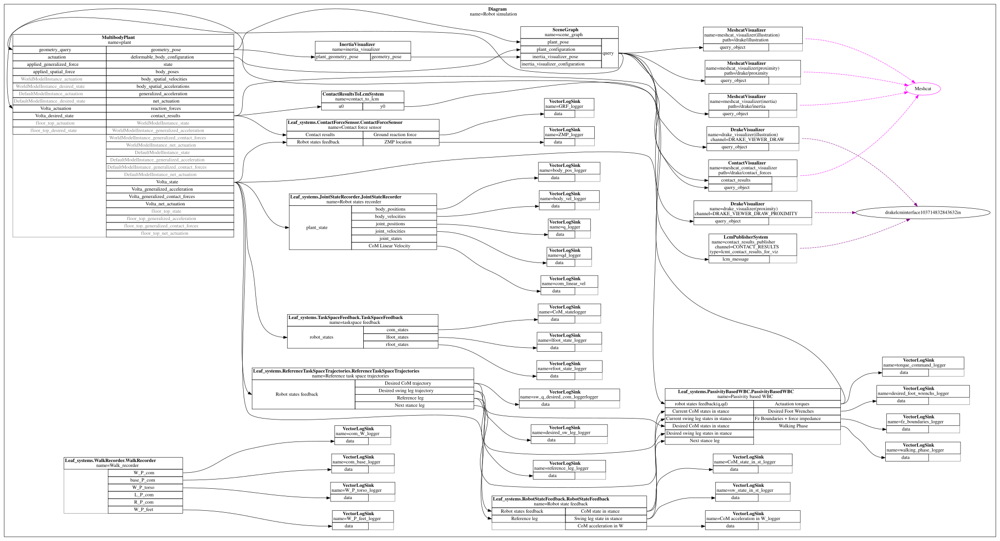

In [19]:
show_diagram(diagram=diagram,show=True)

# Exicute simulation

In [20]:
simulator = Simulator(diagram)
new_context = diagram.CreateDefaultContext()
simulator.reset_context(new_context)
context = simulator.get_mutable_context()

plant_context = plant.GetMyContextFromRoot(context)
walk_recorder.root_context = context
num_positions = plant.num_positions(robot_instant_index[0])  # Get the total number of positions in the plant

body_quanternion_xyzw = np.array([R.from_euler('xyz', init_orien*np.pi/180.0).as_quat()])[0]


body_quanternion_wxyz = [body_quanternion_xyzw[3], body_quanternion_xyzw[0], body_quanternion_xyzw[1], body_quanternion_xyzw[2]]
body_pose = np.concatenate((np.array([body_quanternion_wxyz]), np.array([init_pos])), axis=1)


initial_joint_positions = np.concatenate((np.array([left_q]), np.array([right_q])), axis=1)
initial_joint_velocities = np.concatenate((np.array([left_qd]), np.array([right_qd])), axis=1)
if fixed_base:
    initial_q = initial_joint_positions[0] # fixed base
    initial_qd = initial_joint_velocities[0]
else:
    initial_q = np.concatenate((body_pose, initial_joint_positions),axis=1)[0] # floating base
    initial_qd = np.concatenate((np.zeros([1,6]), initial_joint_velocities),axis=1)[0]

plant.SetPositions(plant_context, robot_instant_index[0], initial_q)
# plant.SetVelocities(plant_context, robot_instant_index[0], initial_qd)
simulator.Initialize()

# if realtime:
# simulator.set_target_realtime_rate(0.15)
meshcat.StartRecording()
# 
simulator.AdvanceTo(sim_time)
meshcat.PublishRecording()

--------------------------------------------------
RTS time:  0.0
--------------------------------------------------
time step: 0.0
Next leg state: double_stance
Current state: double_stance
States change: False
curr com position [ 0.0179 -0.1248  0.3589]
desired com position [ 0.0179 -0.1248  0.3589]
R sw current [0. 0. 0.]
fz ref: [np.float64(34.958182732145566), np.float64(34.86939726785441)]
Optimal cost =  -73141.2217398585
Solver result:  SolutionResult.kSolutionFound
Solver used: Clarabel
generalized position: [ 1.     -0.      0.      0.     -0.     -0.      0.51   -0.505  -0.0016
  0.     -1.2894 -0.7841 -0.0018  0.5022 -0.0022  0.      1.2923  0.7899
 -0.0025]
curr com position in stance: [ 0.0179 -0.1248  0.3588]
--------------------------------------------------
time step: 0.001
Next leg state: double_stance
Current state: double_stance
States change: False
curr com position [ 0.0179 -0.1248  0.3588]
desired com position [ 0.0179 -0.1248  0.3589]
R sw current [ 0.0324 -0.00

In [21]:
com_state_log       = CoM_state_logger.FindLog(context)
lfoot_state_log     = lfoot_state_logger.FindLog(context)
rfoot_state_log     = rfoot_state_logger.FindLog(context)
com_state_data      = com_state_log.data()
lfoot_state_data    = lfoot_state_log.data()
rfoot_state_data    = rfoot_state_log.data()
time = com_state_log.sample_times()

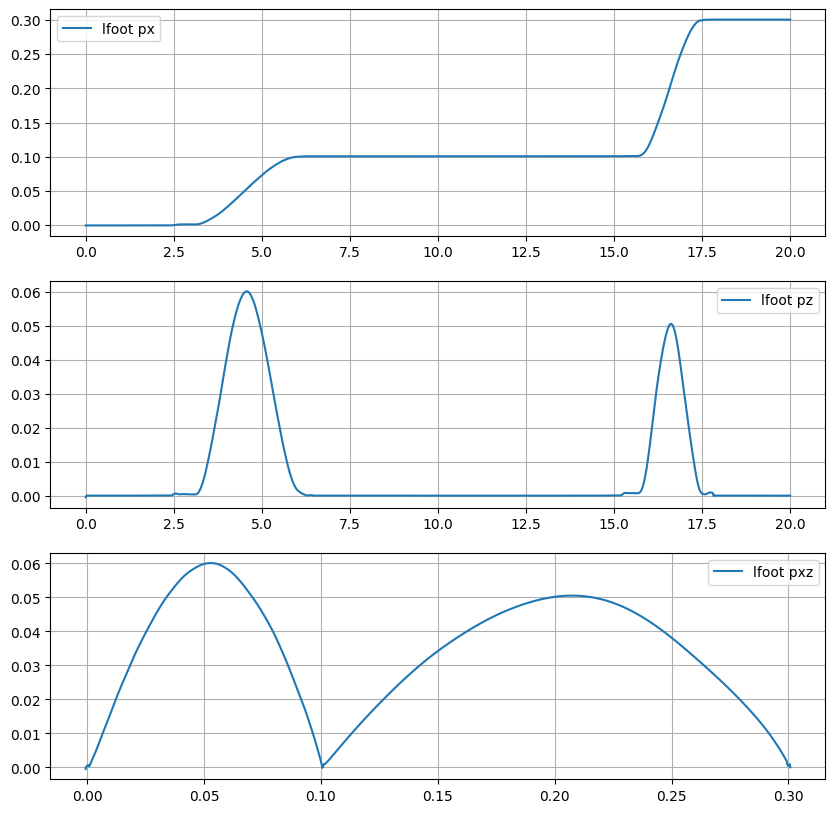

In [22]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(time,rfoot_state_data[3,:],label="lfoot px")
axes[1].plot(time,rfoot_state_data[5,:],label="lfoot pz")
axes[2].plot(rfoot_state_data[3,:],rfoot_state_data[5,:],label="lfoot pxz")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

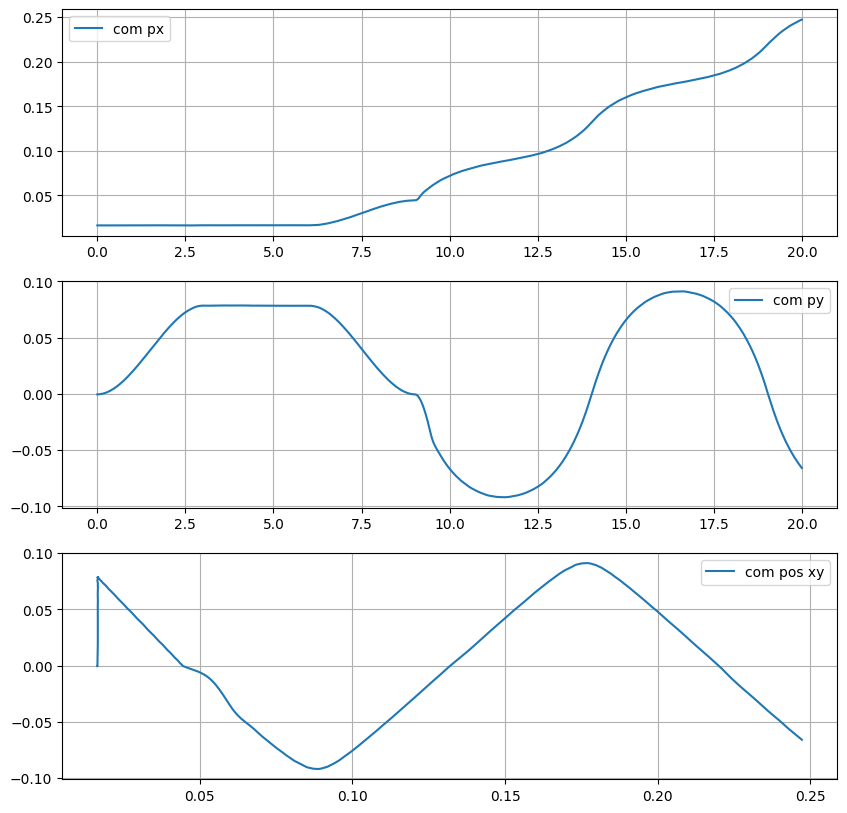

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(time,com_state_data[3,:],label="com px")
axes[1].plot(time,com_state_data[4,:],label="com py")
axes[2].plot(com_state_data[3,:],com_state_data[4,:],label="com pos xy")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

/tmp/ipykernel_9617/4169358066.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


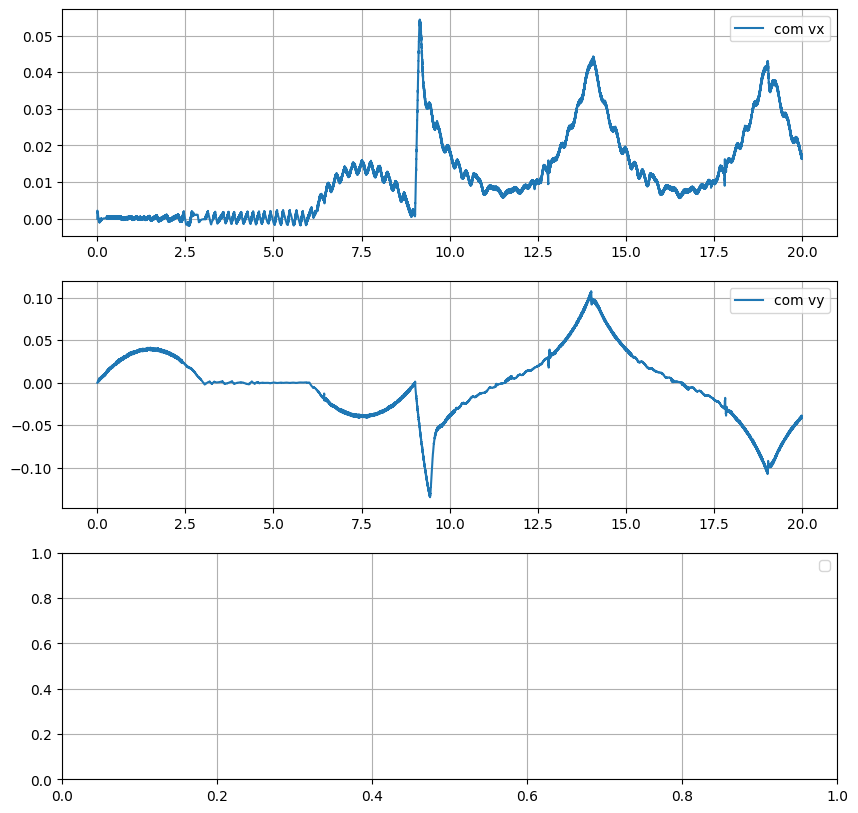

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(time,com_state_data[9,:],label="com vx")
axes[1].plot(time,com_state_data[10,:],label="com vy")
# axes[2].plot(com_state_data[3,:],com_state_data[4,:],label="com pos xy")
for ax in axes:
    ax.grid()
    ax.legend()
plt.show()

# Plot

In [25]:

torque_command_log = torque_command_logger.FindLog(context)
torso_P_com_log = com_base_logger.FindLog(context) 
W_P_torso_log = W_P_torso_logger.FindLog(context)
W_P_com_log = com_W_logger.FindLog(context)
body_pos_log = body_pos_logger.FindLog(context)
body_vel_log = body_vel_logger.FindLog(context)
q_log = q_logger.FindLog(context)
qd_log = qd_logger.FindLog(context)
com_linear_vel_log = com_linear_vel.FindLog(context)
com_acc_in_w_log=com_acc_in_w_logger.FindLog(context)
t = q_log.sample_times()
n = plant.num_positions()
if controller == "PWBC":
    desired_com_log = desired_com_logger.FindLog(context)
    desired_sw_leg_log = desired_sw_leg_logger.FindLog(context) 
    desired_foot_wrenchs_log =  desired_foot_wrenchs_logger.FindLog(context)
    fz_boundaries_log = fz_boundaries_logger.FindLog(context)
    walking_phase_log = walking_phase_logger.FindLog(context)
    CoM_state_in_st_log = CoM_state_in_st_logger.FindLog(context)
    sw_state_in_st_log = sw_state_in_st_logger.FindLog(context)
else:
    if controller == "PWBCm":
        desired_foot_wrenchs_log =  desired_foot_wrenchs_logger.FindLog(context)
        fz_boundaries_log = fz_boundaries_logger.FindLog(context)        
    L_log = sw_q_logger.FindLog(context)
    R_log = st_q_logger.FindLog(context)
    leg_state_log = leg_state_logger.FindLog(context)
    L_qd_log = sw_qd_logger.FindLog(context)
    R_qd_log = st_qd_logger.FindLog(context)

W_P_feet_log = W_P_feet_logger.FindLog(context)
GRF_log = GRF_logger.FindLog(context)

ZMP_log = ZMP_logger.FindLog(context)
dir = "/home/tanawat/Documents/Thesis/Thesis_simulation/Simulation/FinalProgress/Datas/JointDatas/SimulationResult/"


In [26]:
# if controller == "PWBC": 
#     timestamp = desired_com_logger.FindLog(context).sample_times()
#     desired_com_data = desired_com_logger.FindLog(context).data()
#     desired_sw_leg_data = desired_sw_leg_logger.FindLog(context).data() 
#     desired_foot_wrenchs_data =  desired_foot_wrenchs_logger.FindLog(context).data()
#     fz_boundaries_data = fz_boundaries_logger.FindLog(context).data()
#     walking_phase_data = walking_phase_logger.FindLog(context).data()
#     CoM_state_in_st_data = CoM_state_in_st_logger.FindLog(context).data()
#     sw_state_in_st_data = sw_state_in_st_logger.FindLog(context).data()
#     torque_command_data= torque_command_logger.FindLog(context).data()
#     # 1. Define folder and file names
#     folder_name = "/home/tanawatp/Documents/Thesis_simulation/M_result/data"
#     file_name = "DummyExperiment.npz"

#     # 2. Create the folder if it doesn't exist
#     # exist_ok=True prevents an error if the folder is already there
#     os.makedirs(folder_name, exist_ok=True)

#     # 3. Construct the full path (e.g., 'data_logs/experiment_01.npz')
#     full_path = os.path.join(folder_name, file_name)

#     print(f"Saving data to: {full_path}")

#     # 2. Save all variables into one compressed archive
#     # format: key_name = variable_name
#     np.savez_compressed(
#         full_path,
#         timestamp=timestamp,
#         desired_com=desired_com_data,
#         desired_sw_leg=desired_sw_leg_data,
#         desired_foot_wrenchs=desired_foot_wrenchs_data,
#         fz_boundaries=fz_boundaries_data,
#         walking_phase=walking_phase_data,
#         CoM_state_in_st=CoM_state_in_st_data,
#         sw_state_in_st=sw_state_in_st_data,
#         torque_command_data=torque_command_data
#     )

#     print("Save complete.")

In [27]:
def PlotGRF(desired_foot_wrenchs_log,GRF_log,boundary):
    GRF_data = GRF_log.data()
    desired_foot_wrenchs_data = desired_foot_wrenchs_log.data()
    fz_boundaries_data = fz_boundaries_log.data()
    time_data = GRF_log.sample_times()
    wrench_L = GRF_data[0:6]
    wrench_R = GRF_data[6:12]
    desired_wrench_L = desired_foot_wrenchs_data[0:6]
    desired_wrench_R = desired_foot_wrenchs_data[6:12] 
    start = int(boundary[0]*10000) + 1000
    if boundary[1] <= 0:
        stop = len(time_data)
    else:
        stop = int(boundary[1]*10000)
    label = ["moment x","moment y","moment z","force x","force y [N]","force z [N]"]
    for i in [5]:
        plt.figure(figsize=(10,6))
        # plt.plot(time_data[start:stop], wrench_L[i,start:stop], label=f'Left {label[i]}', color='b')
        # plt.plot(time_data[start:stop], wrench_R[i,start:stop], label=f'Right {label[i]}', color='r')
        plt.plot(time_data[start:stop], desired_wrench_L[i,start:stop], label=f'Desired Left {label[i]}', color='r', linestyle="--")
        plt.plot(time_data[start:stop], desired_wrench_R[i,start:stop], label=f'Desired Right {label[i]}', color='b', linestyle="--")
        if i ==5:
            # plt.plot(time_data[start:stop], fz_boundaries_data[0,start:stop], label=f'Min L {label[i]}', color='g')
            # plt.plot(time_data[start:stop], fz_boundaries_data[1,start:stop], label=f'Max L {label[i]}', color='g', linestyle="--")
            plt.plot(time_data[start:stop], fz_boundaries_data[2,start:stop], label=f'Min R {label[i]}', color='orange')
            plt.plot(time_data[start:stop], fz_boundaries_data[3,start:stop], label=f'Max R {label[i]}', color='g')
            # plt.plot(time_data[start:stop], fz_boundaries_data[4,start:stop], label=f'f_imp {label[i]}')
        plt.title('Ground Reaction Forces over Time')
        plt.xlabel('Time [s]') 
        plt.ylabel(label[i])
        plt.legend()
        plt.grid()
        plt.show()

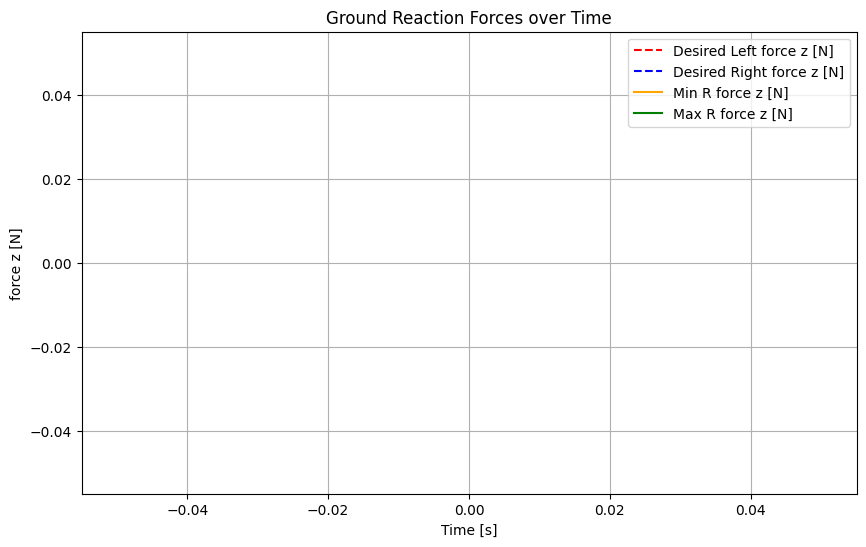

In [28]:
if controller == "PWBC": 
        PlotGRF(desired_foot_wrenchs_log=desired_foot_wrenchs_log,
                GRF_log=GRF_log,
                boundary=[2.2,2.5])

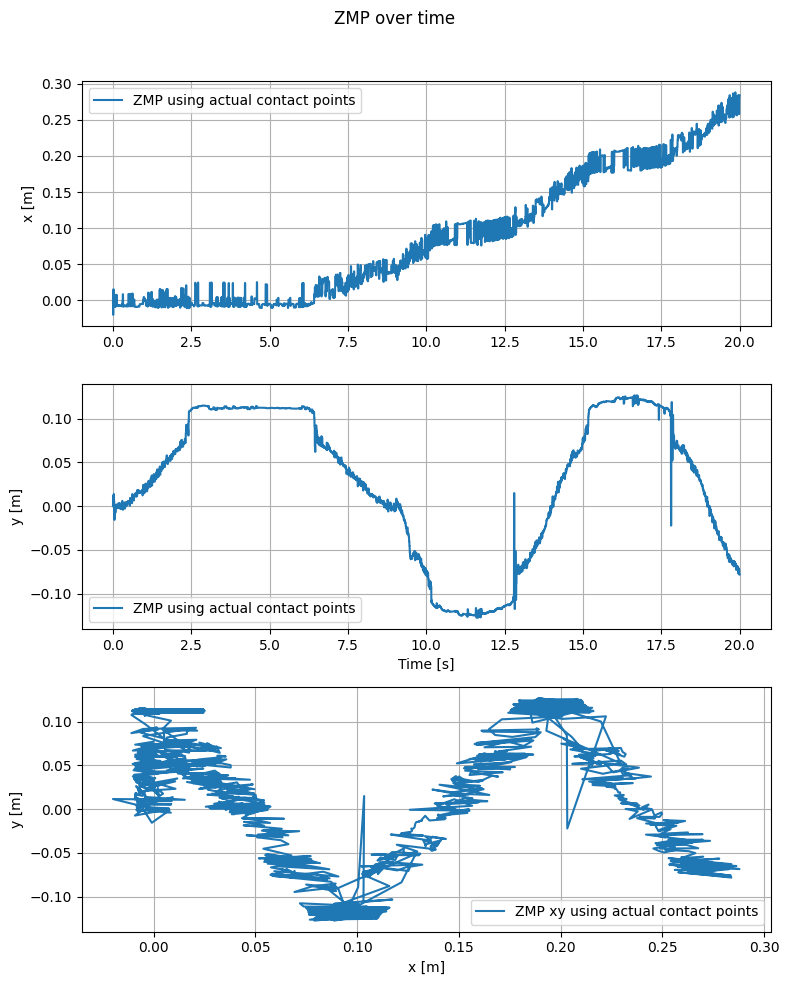

In [29]:
time = ZMP_log.sample_times()
com_acc_in_w_data = ZMP_log.data()
fig, axs = plt.subplots(3, 1, figsize=(8, 10))
labels = ["x [m]","y [m]","z [m]"]
offset = [0.0,-0.0,0.0]
start = 0.5 * 10000
stop = sim_time * 10000
start = int(start)
stop = int(stop)
t = time[start:stop]
for i in range(2):
    axs[i].plot(time,com_acc_in_w_data[i,:], label=f'ZMP using actual contact points')
    # axs[i].plot(time,com_acc_in_w_data[i+2,:], label=f'ZMP using fixed contact points')
    # axs[i].plot(time[500:stop],actual_sw_foot_position[i,500:stop], label=f'Actual')
    # axs[i].plot(t,desired_sw_leg_data[i,start:stop], label=f'Deired position', linestyle="--")
    axs[i].set_ylabel(labels[i])
    axs[i].grid(True)
    axs[i].legend()
axs[2].plot(com_acc_in_w_data[0,:],com_acc_in_w_data[1,:], label=f'ZMP xy using actual contact points')
# axs[2].plot(com_acc_in_w_data[2,:],com_acc_in_w_data[3,:], label=f'ZMP xy using fixed contact points')
axs[-1].set_xlabel("x [m]")
axs[-2].set_xlabel("Time [s]")
axs[2].set_ylabel(labels[i])
axs[2].grid(True)
axs[2].legend()
plt.suptitle("ZMP over time")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

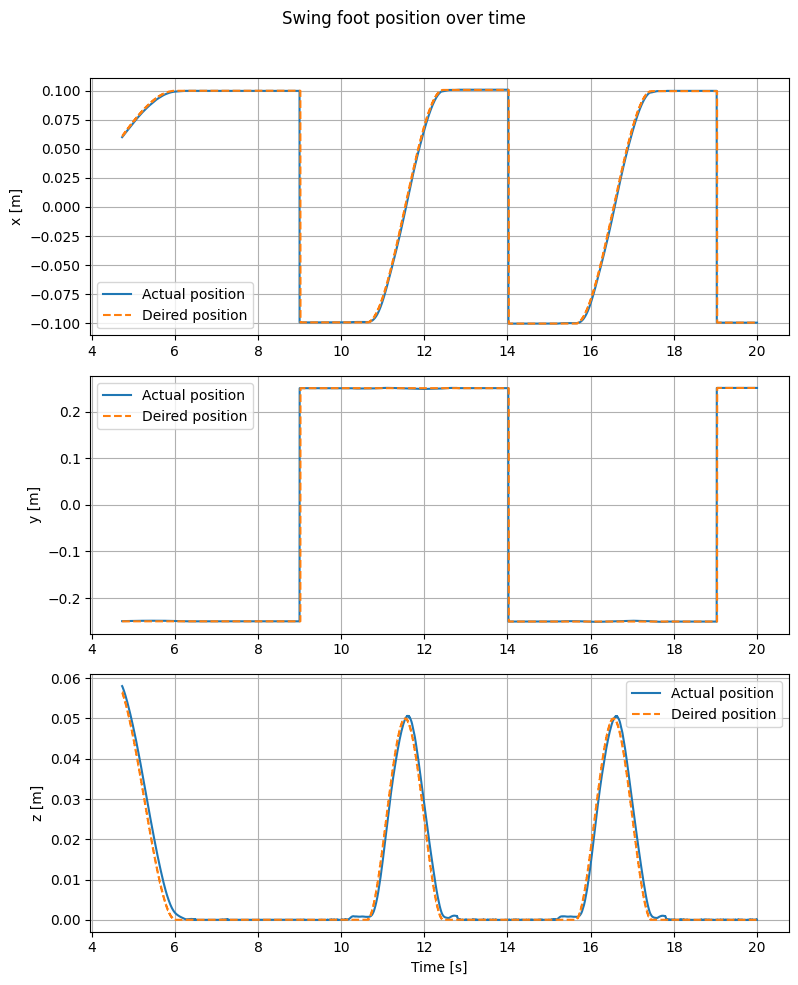

In [30]:
if controller == "PWBC":
    sw_state_in_st_data = sw_state_in_st_log.data()
    sw_orientation_in_st_data = sw_state_in_st_data[0:3,:]
    sw_position_in_st_data = sw_state_in_st_data[3:6,:]
    sw_angular_velocity_in_st_data = sw_state_in_st_data[6:9,:]
    sw_linear_velocity_in_st_data = sw_state_in_st_data[9:12,:]
    W_P_feet_data = W_P_feet_log.data()
    W_P_L = W_P_feet_data[0:3,:]
    W_P_R = W_P_feet_data[3:,:]
    desired_sw_leg_data = desired_sw_leg_log.data()
    time = W_P_feet_log.sample_times()
    fig, axs = plt.subplots(3, 1, figsize=(8, 10))
    labels = ["x [m]","y [m]","z [m]"]
    offset = [0.0,-0.0,0.0]
    start = 0.5 * 10000
    stop = sim_time * 10000
    start = int(start)
    stop = int(stop)
    t = time[start:stop]
    for i in range(3):
        axs[i].plot(t,sw_position_in_st_data[i,start:stop]+offset[i], label=f'Actual position')
        # axs[i].plot(time[500:stop],actual_sw_foot_position[i,500:stop], label=f'Actual')
        axs[i].plot(t,desired_sw_leg_data[i,start:stop], label=f'Deired position', linestyle="--")
        axs[i].set_ylabel(labels[i])
        axs[i].grid(True)
        axs[i].legend()

    axs[-1].set_xlabel("Time [s]")
    plt.suptitle("Swing foot position over time")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

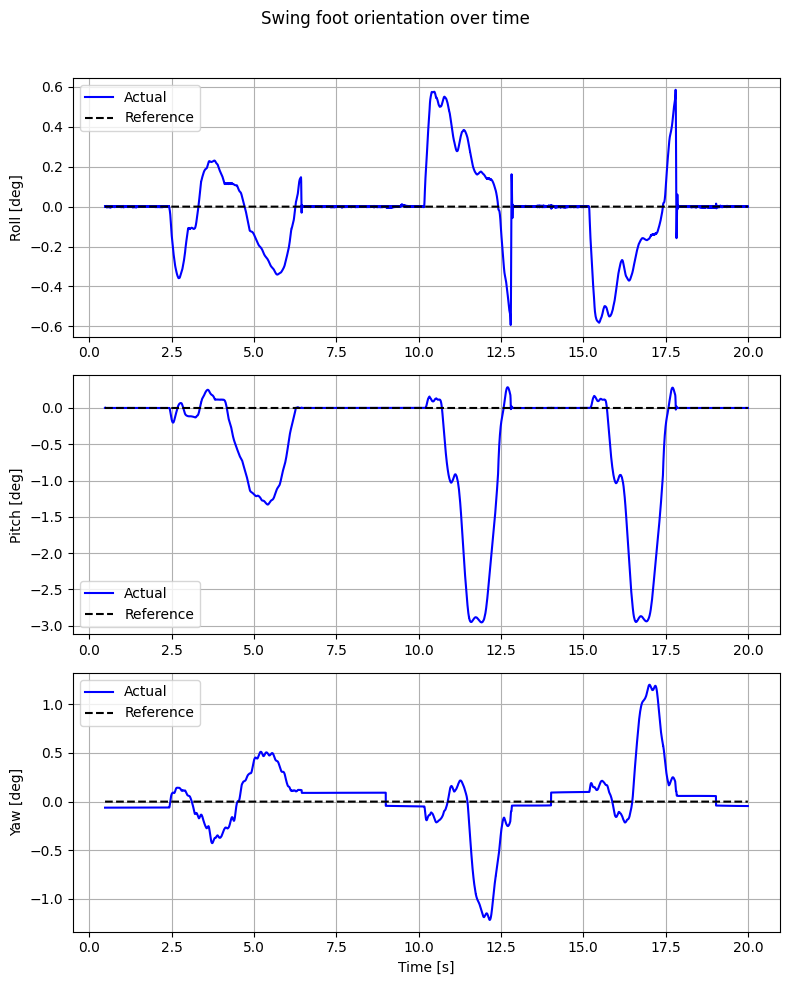

In [31]:
if controller=="PWBC":
    W_P_feet_data = W_P_feet_log.data()
    W_P_L = W_P_feet_data[0:3,:]
    W_P_R = W_P_feet_data[3:,:]
    desired_sw_leg_data = desired_sw_leg_log.data()
    time = W_P_feet_log.sample_times()
    fig, axs = plt.subplots(3, 1, figsize=(8, 10))
    labels = ["Roll [deg]","Pitch [deg]","Yaw [deg]"]
    offset = [0.0,-0.0,0.0]
    stop = sim_time * 10000
    stop = int(stop)
    t = time[500:stop]
    for i in range(3):
        axs[i].plot(t,sw_orientation_in_st_data[i,500:stop]*180.0/np.pi, label=f'Actual',color='b')
        # axs[i].plot(time[500:stop],actual_sw_foot_position[i,500:stop], label=f'Actual')
        axs[i].plot(t,np.zeros(t.shape[0]), label=f'Reference', linestyle="--",color='black')
        axs[i].set_ylabel(labels[i])
        axs[i].grid(True)
        axs[i].legend()

    axs[-1].set_xlabel("Time [s]")
    plt.suptitle("Swing foot orientation over time")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

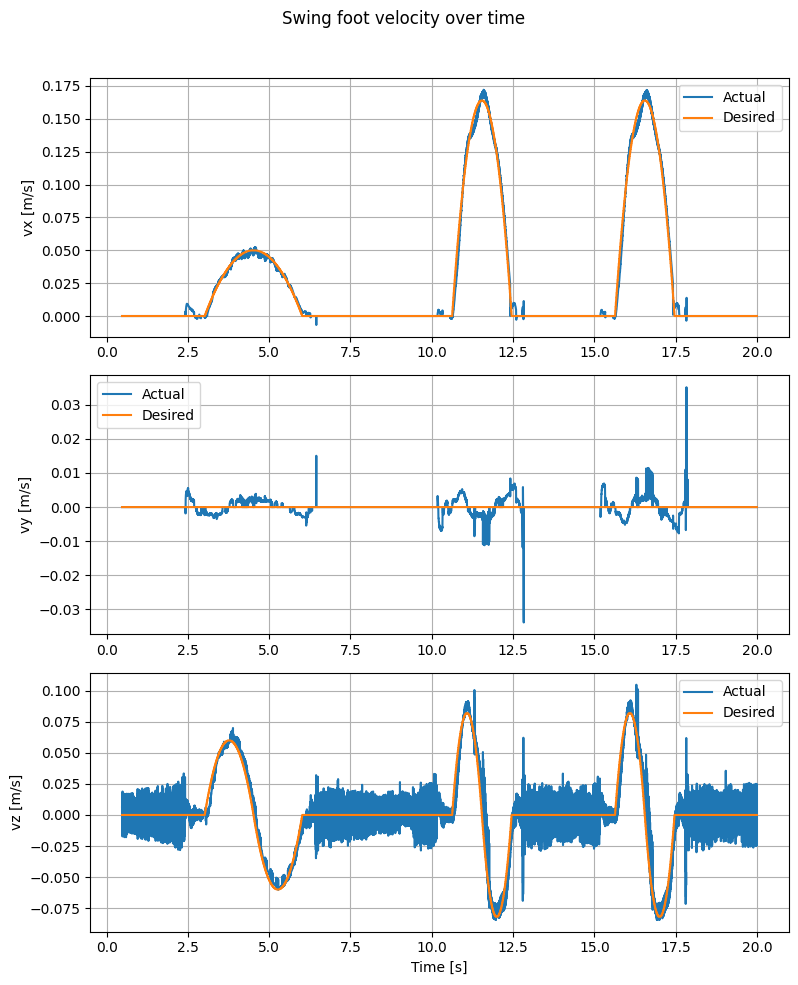

In [32]:
if controller == "PWBC":
    sw_state_in_st_data = sw_state_in_st_log.data()
    sw_orientation_in_st_data = sw_state_in_st_data[0:3,:]
    sw_position_in_st_data = sw_state_in_st_data[3:6,:]
    sw_angular_velocity_in_st_data = sw_state_in_st_data[6:9,:]
    sw_linear_velocity_in_st_data = sw_state_in_st_data[9:12,:]
    fig, axs = plt.subplots(3, 1, figsize=(8, 10))
    labels = ["vx [m/s]","vy [m/s]","vz [m/s]"]
    offset = [0.0,-0.0,0.0]
    # stop = sim_time * 10000
    # stop = int(stop)
    for i in range(3):
        axs[i].plot(time[500:stop],sw_linear_velocity_in_st_data[i,500:stop]+offset[i], label=f'Actual')
        axs[i].plot(time[500:stop],desired_sw_leg_data[i+3,500:stop], label=f'Desired')
        axs[i].set_ylabel(labels[i])
        axs[i].grid(True)
        axs[i].legend()

    axs[-1].set_xlabel("Time [s]")
    plt.suptitle("Swing foot velocity over time")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

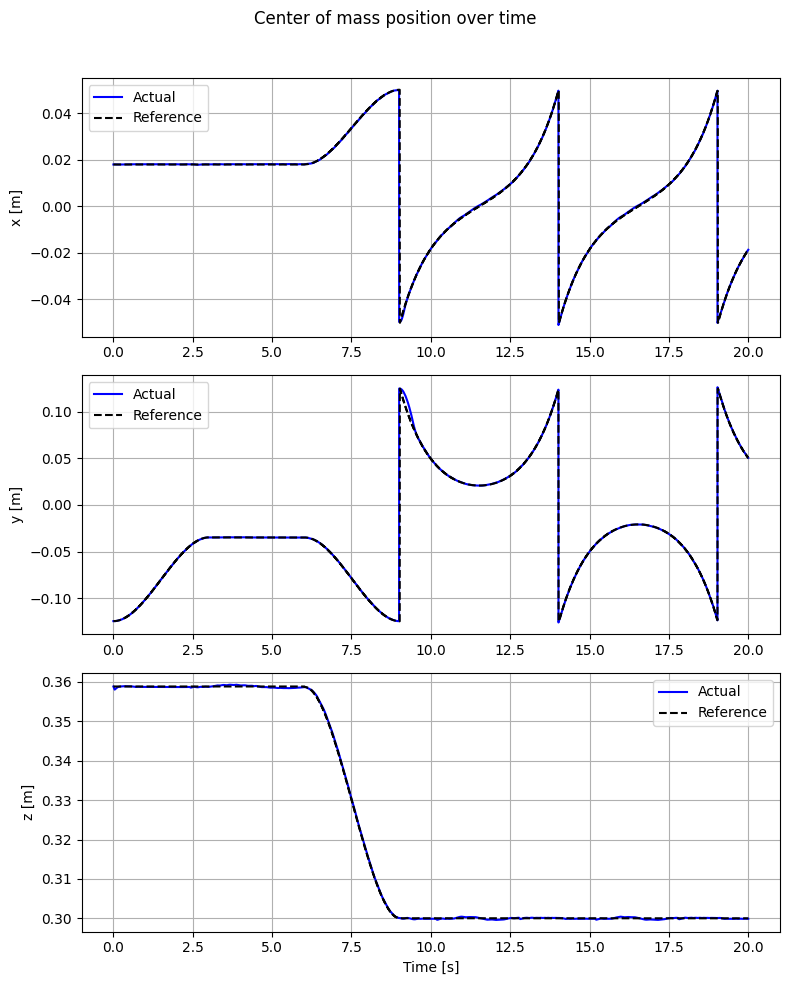

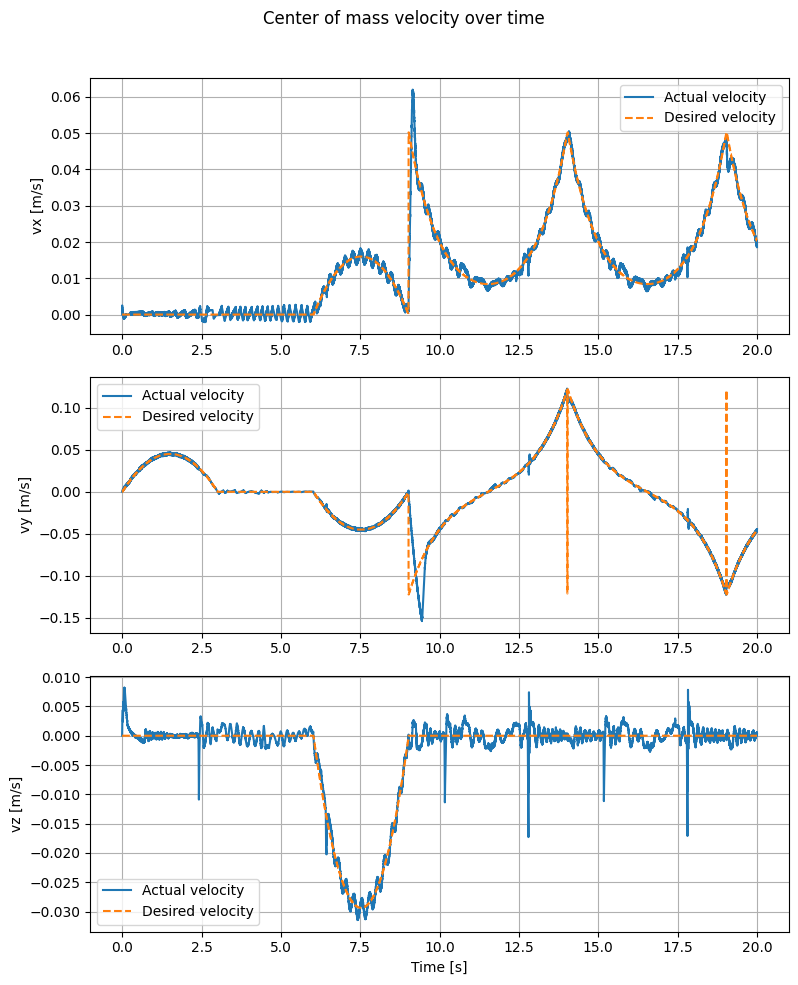

In [33]:
if controller == "PWBC":
    CoM_state_in_st_data = CoM_state_in_st_log.data()
    CoM_orientation_in_st_data = CoM_state_in_st_data[0:3,:]
    CoM_position_in_st_data = CoM_state_in_st_data[3:6,:]
    CoM_linear_velocity_in_st_data = CoM_state_in_st_data[9:12,:]
    # CoM_linear_velocity_via_momentum_data = CoM_linear_velocity_via_momentum_log.data()
    desired_com_data = desired_com_log.data()
    fig, axs = plt.subplots(3, 1, figsize=(8, 10))
    labels = ["x [m]","y [m]","z [m]"]
    offset = [0.0,-0.0,0.0]
    start = 0* 10000
    stop = sim_time* 10000
    start = int(start)
    stop = int(stop)
    t = time[start:stop]
    for i in range(3):
        axs[i].plot(t,CoM_position_in_st_data[i,start:stop], label=f'Actual',color='b')
        axs[i].plot(t,desired_com_data[i,start:stop], label=f'Reference', linestyle="--",color='black')
        axs[i].set_ylabel(labels[i])
        axs[i].grid(True)
        axs[i].legend()

    axs[-1].set_xlabel("Time [s]")
    plt.suptitle("Center of mass position over time")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    fig, axs = plt.subplots(3, 1, figsize=(8, 10))
    labels = ["vx [m/s]","vy [m/s]","vz [m/s]"]
    offset = [0.0,-0.0,0.0]
    t = time[start:stop]
    for i in range(3):
        axs[i].plot(t,CoM_linear_velocity_in_st_data[i,start:stop], label=f'Actual velocity')
        axs[i].plot(t,desired_com_data[i+3,start:stop], label=f'Desired velocity', linestyle="--")
        axs[i].set_ylabel(labels[i])
        axs[i].grid(True)
        axs[i].legend()

    axs[-1].set_xlabel("Time [s]")
    plt.suptitle("Center of mass velocity over time")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

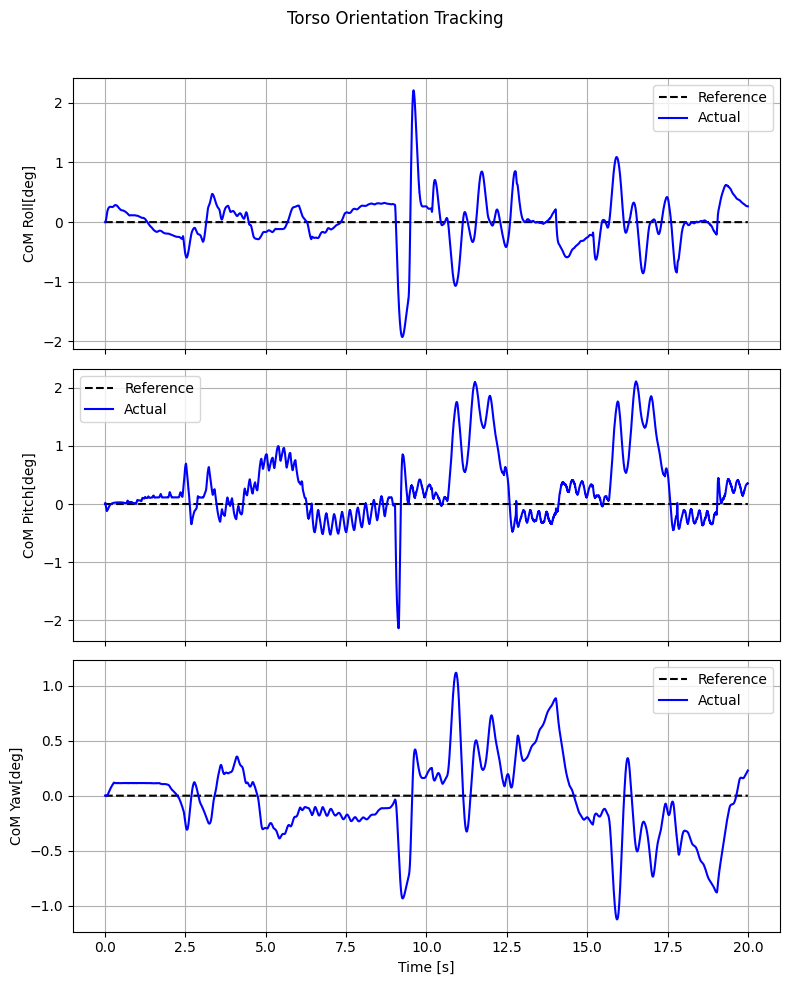

In [34]:
if controller == "PWBC":    
    fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)
    time_des = desired_com_log.sample_times()[1:]
    time_act = W_P_com_log.sample_times()[1:]
    CoM_state_in_st_data = CoM_state_in_st_log.data()
    torso_orientation = CoM_state_in_st_data[0:3,:].T * 180.0/np.pi
    labels = ["CoM Roll[deg]", "CoM Pitch[deg]", "CoM Yaw[deg]"]
    ref = [0,0,0]
    for i in range(3):
        axs[i].plot(time_des, np.zeros(time_des.shape[0])+ref[i], label="Reference", linestyle="--",color='black')
        axs[i].plot(time_act, torso_orientation[1:,i], label="Actual", linestyle="-",color='b')
        # axs[i].plot(time_act, torso_orietation_data[1:,i]*180.0/np.pi, label="Actual2", linestyle="-")
        axs[i].set_ylabel(labels[i])
        axs[i].grid(True)
        axs[i].legend()

    axs[-1].set_xlabel("Time [s]")
    plt.suptitle(f"Torso Orientation Tracking")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

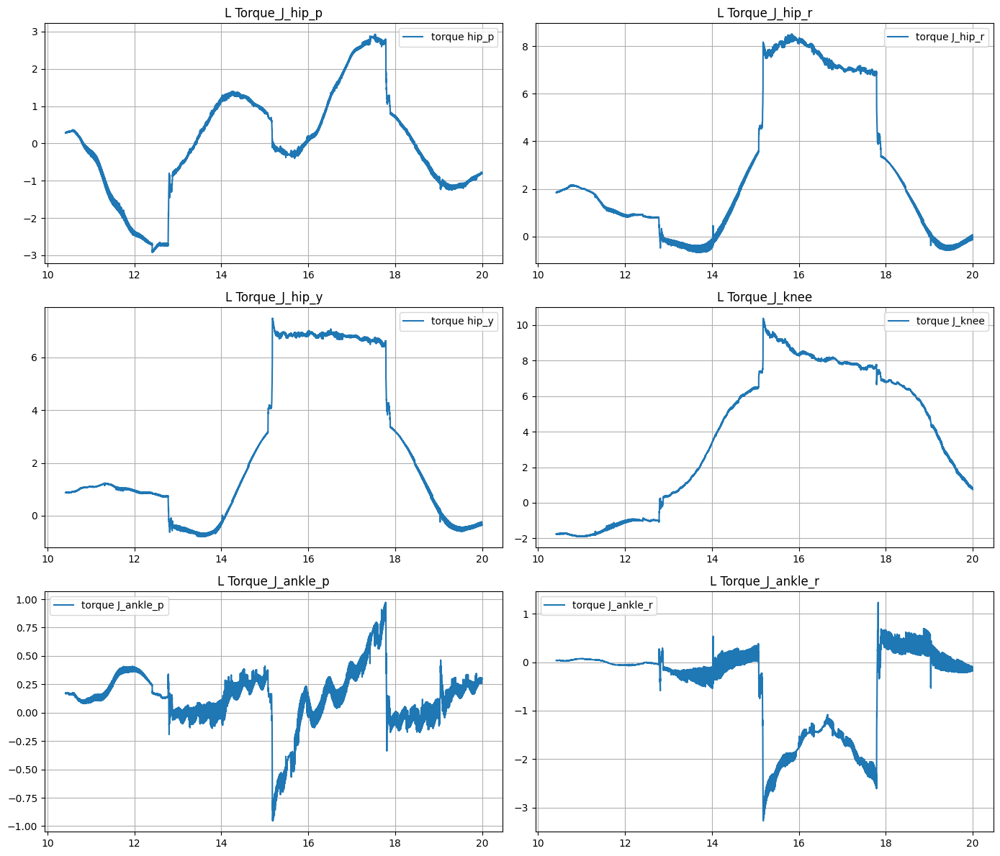

In [35]:
name = ["J_hip_p","J_hip_r","J_hip_y","J_knee","J_ankle_p","J_ankle_r"]
fig, axs = plt.subplots(3, 2, figsize=(14, 12))
start = 11000
stop = len(q_log.sample_times()) #- 3000
# stop = 13500
for i in range(6):
    temp = name[i]
    ax = axs[i // 2, i % 2]
    if i == 2:
        ax.plot(q_log.sample_times()[start:stop], torque_command_log.data()[0, start:stop], label="torque hip_y")
    elif i==0:
        ax.plot(q_log.sample_times()[start:stop], torque_command_log.data()[2, start:stop], label="torque hip_p")
    else:
        ax.plot(q_log.sample_times()[start:stop], torque_command_log.data()[i, start:stop], label=f"torque {temp}")
    # if controller_enable:
    #     ax.plot(q_log.sample_times(), q_err_log.data()[i, :], label="L Joint error", color="green")

    ax.set_title(f"L Torque_{temp}")
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()

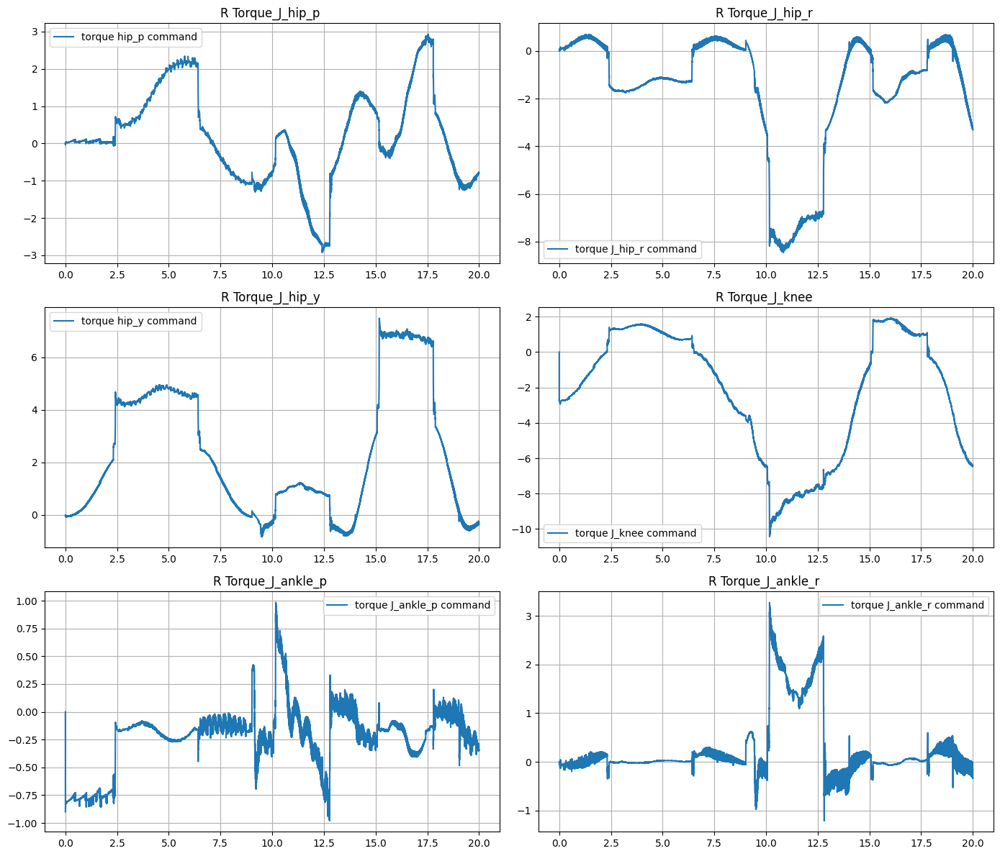

In [36]:
name = ["J_hip_p","J_hip_r","J_hip_y","J_knee","J_ankle_p","J_ankle_r"]
fig, axs = plt.subplots(3, 2, figsize=(14, 12))
for i in range(6):
    temp = name[i]
    ax = axs[i // 2, i % 2]
    i+=6
    if i == 8:
        ax.plot(q_log.sample_times(), torque_command_log.data()[0, :], label="torque hip_y command")
    elif i==6:
        ax.plot(q_log.sample_times(), torque_command_log.data()[2, :], label="torque hip_p command")
    else:
        ax.plot(q_log.sample_times(), torque_command_log.data()[i, :], label=f"torque {temp} command")
    # if controller_enable:
    #     ax.plot(q_log.sample_times(), q_err_log.data()[i, :], label="L Joint error", color="green")

    ax.set_title(f"R Torque_{temp} ")
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()

IndexError: index 3 is out of bounds for axis 0 with size 3

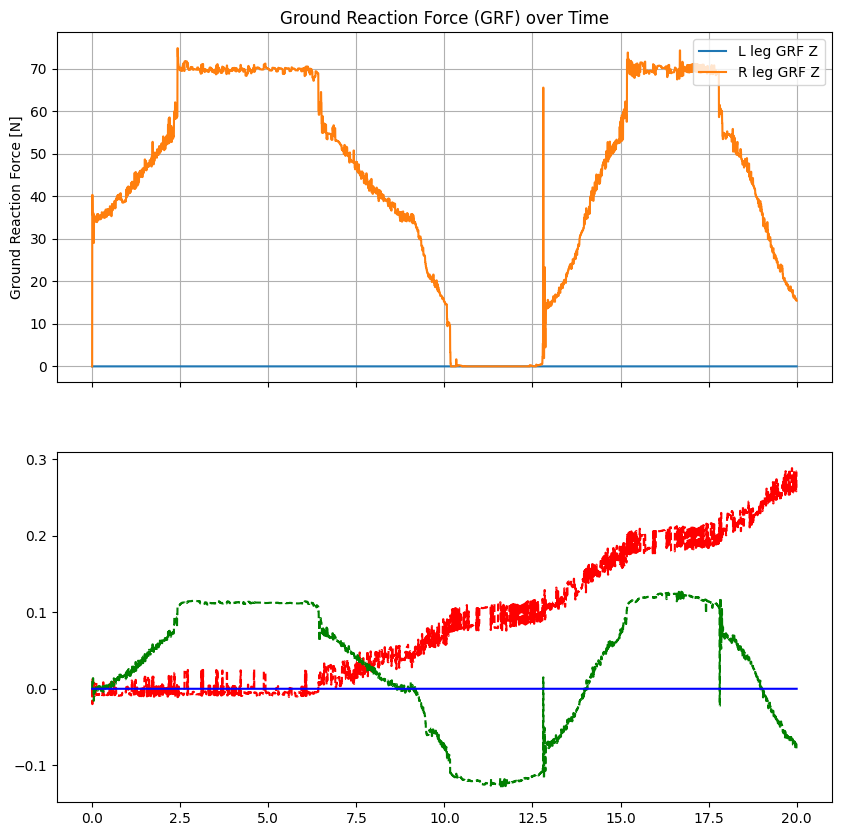

In [37]:
import matplotlib.pyplot as plt

# Set your desired time window here
start_time = 0.0  # e.g., 0.02 s
end_time = sim_time   # e.g., 0.03 s

# Get time array from GRF_log (assuming all logs have the same time base)
time = GRF_log.sample_times()
mask = (time >= start_time) & (time <= end_time)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# Plot GRF_log for both legs (Z axis)
ax1.plot(time[mask], GRF_log.data()[2, mask], label='L leg GRF Z')
ax1.plot(time[mask], GRF_log.data()[5, mask], label='R leg GRF Z')
ax1.set_ylabel('Ground Reaction Force [N]')
ax1.legend(loc='upper right')
ax1.grid(True)
ax1.set_title('Ground Reaction Force (GRF) over Time')

# Plot ZMP_log for both legs (X and Y) and index 3 and 4 in the same figure
ax2.plot(ZMP_log.sample_times()[mask], ZMP_log.data()[0, mask], 'r--', label='L leg ZMP X')
ax2.plot(ZMP_log.sample_times()[mask], ZMP_log.data()[1, mask], 'g--', label='L leg ZMP Y')
ax2.plot(ZMP_log.sample_times()[mask], ZMP_log.data()[2, mask], 'b-', label='R leg ZMP X')
ax2.plot(ZMP_log.sample_times()[mask], ZMP_log.data()[3, mask], 'm-', label='R leg ZMP Y')
ax2.set_xlabel('Time [s]')
ax2.set_ylabel('ZMP [m]')
ax2.legend(loc='upper right')
ax2.grid(True)
ax2.set_title('Zero Moment Point (ZMP) over Time')

plt.tight_layout()
plt.show()

### q vs time

NameError: name 'L_log' is not defined

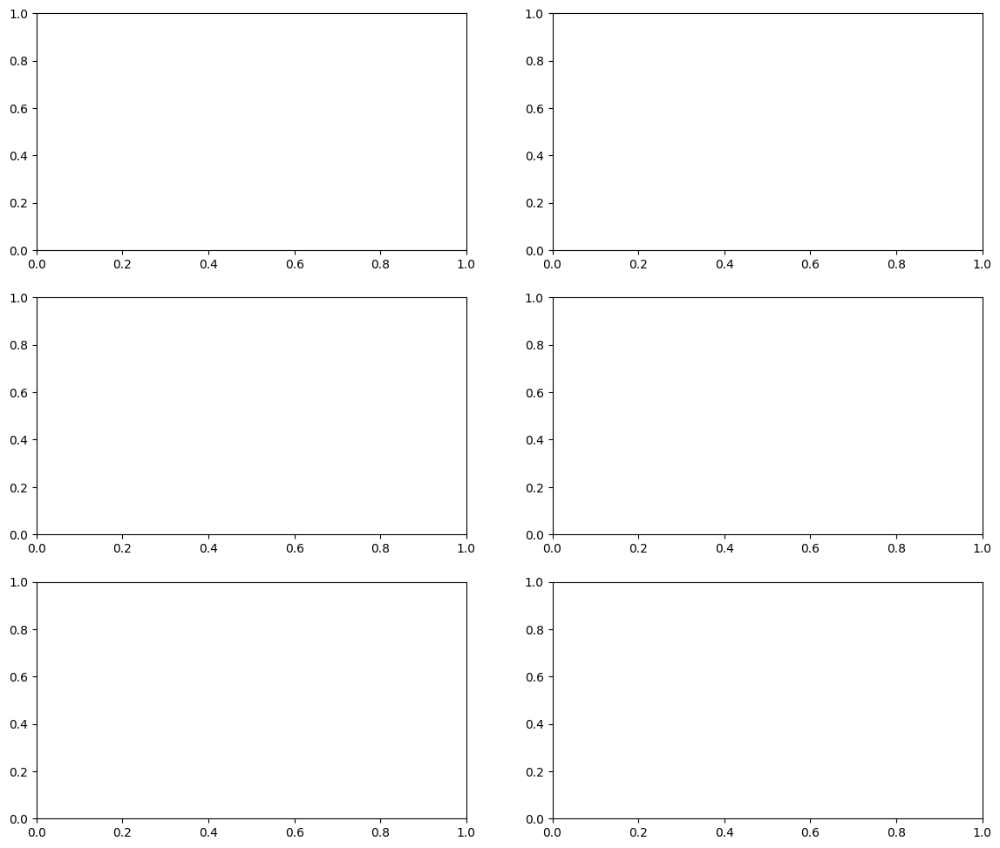

In [ ]:
name = ["J_hip_p","J_hip_r","J_hip_y","J_knee","J_ankle_p","J_ankle_r"]
fig, axs = plt.subplots(3, 2, figsize=(14, 12))
for i in range(6):
    temp = name[i]
    ax = axs[i // 2, i % 2]
    if controller_enable:
        ax.plot(q_log.sample_times(), L_log.data()[i, :], label="Desire L Joint Trajectory")
        # ax.plot(q_log.sample_times(), q_err_log.data()[i, :], label="L Joint error")
    if controller_enable == False and gravity_compensation_enable:
        ax.plot(q_log.sample_times(), np.ones(q_log.sample_times().shape[0])*left_q[i], label="L Desire Joint Position")
    ax.plot(q_log.sample_times(), q_log.data()[i, :], label="L Joint Actual Position")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("q [rad]")
    ax.set_title(f"L_{temp} vs Time")
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()


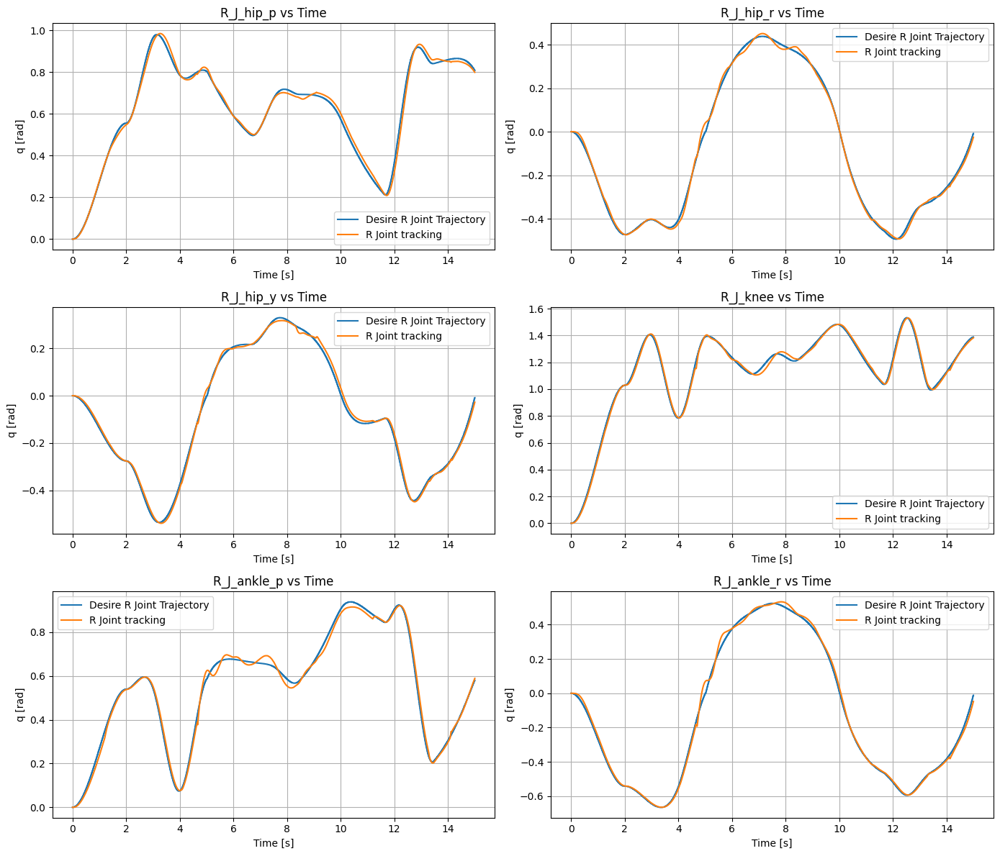

In [ ]:
name = ["J_hip_p","J_hip_r","J_hip_y","J_knee","J_ankle_p","J_ankle_r"]
fig, axs = plt.subplots(3, 2, figsize=(14, 12))
for i in range(6):
    temp = name[i]
    ax = axs[i // 2, i % 2]
    if controller_enable:
        ax.plot(q_log.sample_times(), R_log.data()[i, :], label="Desire R Joint Trajectory")
        # ax.plot(q_log.sample_times(), q_err_log.data()[i+6, :], label="R Joint error")
    ax.plot(q_log.sample_times(), q_log.data()[i+6, :], label="R Joint tracking")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("q [rad]")
    ax.set_title(f"R_{temp} vs Time")
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()

### qd vs time

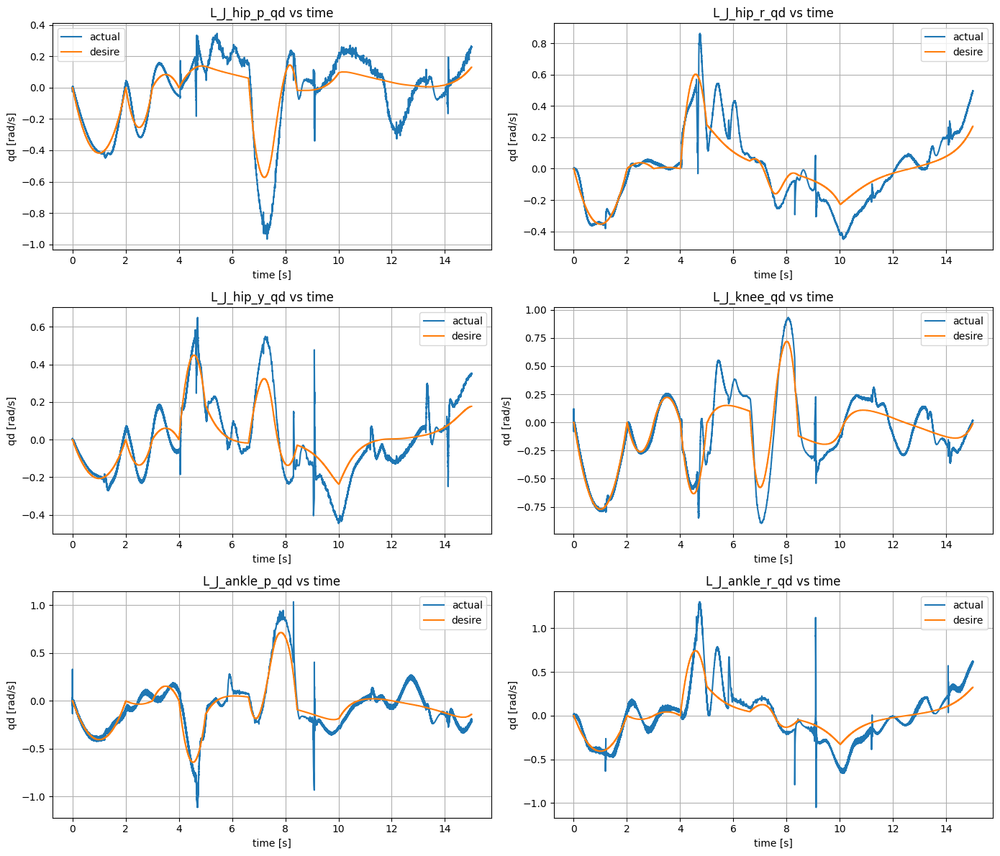

In [ ]:
fig, axs = plt.subplots(3, 2, figsize=(14, 12))
for i in range(6):
    temp = name[i]
    ax = axs[i // 2, i % 2]
    ax.plot(L_qd_log.sample_times(), qd_log.data()[i, :], label="actual")
    ax.plot(L_qd_log.sample_times(), L_qd_log.data()[i, :], label="desire")
    ax.set_xlabel("time [s]")
    ax.set_ylabel("qd [rad/s]")
    ax.set_title(f"L_{temp}_qd vs time")
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()


### torque vs time

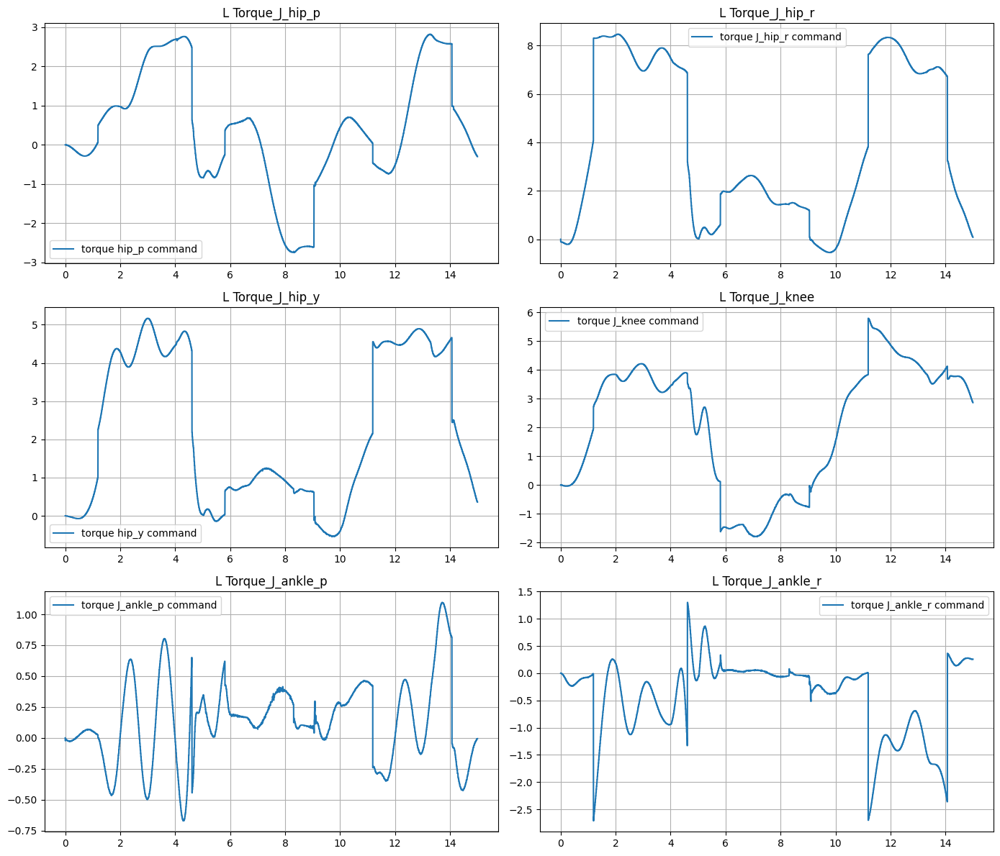

In [ ]:
name = ["J_hip_p","J_hip_r","J_hip_y","J_knee","J_ankle_p","J_ankle_r"]
fig, axs = plt.subplots(3, 2, figsize=(14, 12))
for i in range(6):
    temp = name[i]
    ax = axs[i // 2, i % 2]
    if i == 2:
        ax.plot(q_log.sample_times(), torque_command_log.data()[0, :], label="torque hip_y command")
    elif i==0:
        ax.plot(q_log.sample_times(), torque_command_log.data()[2, :], label="torque hip_p command")
    else:
        ax.plot(q_log.sample_times(), torque_command_log.data()[i, :], label=f"torque {temp} command")
    # if controller_enable:
    #     ax.plot(q_log.sample_times(), q_err_log.data()[i, :], label="L Joint error", color="green")

    ax.set_title(f"L Torque_{temp}")
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()

### CoM plot

In [ ]:
torso_P_com_log = com_base_logger.FindLog(context) 
W_P_torso_log = W_P_torso_logger.FindLog(context)
W_P_com_log = com_W_logger.FindLog(context)
t = q_log.sample_times()

In [ ]:
W_P_torso_log.data().shape

(3, 150998)

In [ ]:
W_P_com_x = W_P_com_log.data()[0,:]
W_P_com_y = W_P_com_log.data()[1,:]
W_P_com_z = W_P_com_log.data()[2,:]
W_P_torso_x = W_P_torso_log.data()[0,:]
W_P_torso_y = W_P_torso_log.data()[1,:]
W_P_torso_z = W_P_torso_log.data()[2,:]

In [ ]:
# index = np.where(W_P_com_y >= 0.125)[0][0]
# print(index*0.0001)

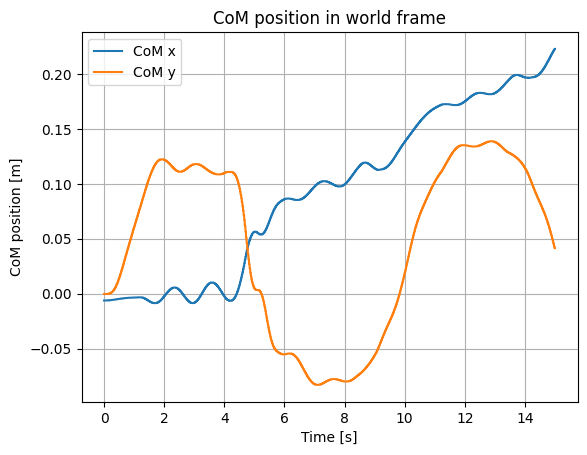

In [ ]:
plt.plot(t, W_P_com_x, label="CoM x")
plt.plot(t, W_P_com_y, label="CoM y")
plt.grid()
plt.xlabel("Time [s]")
plt.ylabel("CoM position [m]")
plt.title("CoM position in world frame")
plt.legend()
plt.show()

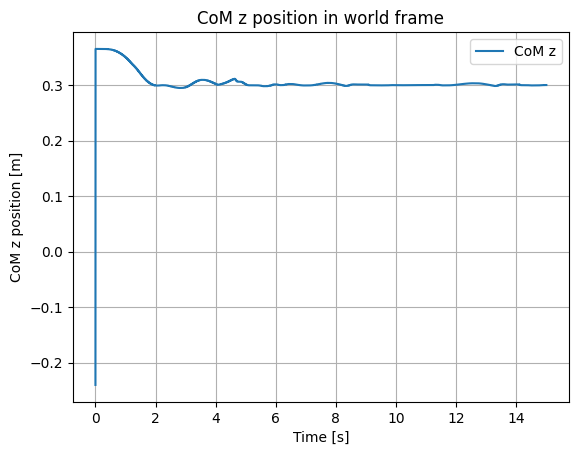

In [ ]:
plt.plot(t, W_P_com_z, label="CoM z")
plt.grid()
plt.xlabel("Time [s]")
plt.ylabel("CoM z position [m]")
plt.title("CoM z position in world frame")
plt.legend()
plt.show()

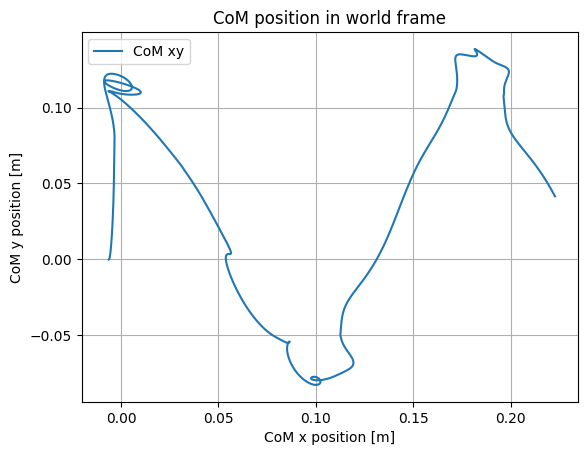

In [ ]:
plt.plot(W_P_com_x,W_P_com_y, label="CoM xy")
plt.grid()
plt.xlabel("CoM x position [m]")
plt.ylabel("CoM y position [m]")
plt.title("CoM position in world frame")
plt.legend()
plt.show()

In [ ]:
def DisplayGait3(x_data, y_data,x_data2, y_data2,x_data3, y_data3, rectangle_centers, rectangle_size):
    # Create a figure and axis
    fig, ax = plt.subplots(figsize=(10, 8))
    # Add rectangles
    for center in rectangle_centers:
        rect_x = center[0] - rectangle_size[0] / 2  # Bottom-left corner x
        rect_y = center[1] - rectangle_size[1] / 2  # Bottom-left corner y
        edge_color = "green" if center[1] < 0 else "red"
        rectangle = patches.Rectangle(
            (rect_x+0.015, rect_y),
            rectangle_size[0],
            rectangle_size[1],
            edgecolor=edge_color,
            facecolor=edge_color,
            alpha=0.3, 
            linewidth=2,
        )
        ax.add_patch(rectangle)
    # Plot the trajectory
    ax.scatter(x_data, y_data, label="Desire CoM Trajectory", color="blue",s=0.1, linewidth=1)
    ax.plot(x_data2, y_data2, label="Actual CoM Trajectory", color="black", linewidth=1)
    ax.plot(x_data3, y_data3, label="Actual torso Trajectory", color="red", linewidth=1)
    # Set equal scaling for x and y axes
    ax.set_aspect("equal")

    # Set equal resolution by matching axis limits
    x_min, x_max = min(x_data) - 0.1, max(x_data) + 0.1
    y_min, y_max = min(y_data) - 0.1, max(y_data) + 0.1
    max_range = max(x_max - x_min, y_max - y_min)

    # Set tick steps to 0.1
    x_ticks = np.arange(-0.05, x_max, 0.1)
    y_ticks = np.arange(-0.1, 0.15, 0.1)
    ax.set_xticks(x_ticks)
    ax.set_yticks(y_ticks)

    # Set plot labels and legend
    ax.set_xlabel('X [m]')
    ax.set_ylabel('Y [m]')
    ax.set_title('CoM Trajectory Tracking Result')
    ax.legend()
    ax.grid(True)

    # Display the plot
    plt.show()

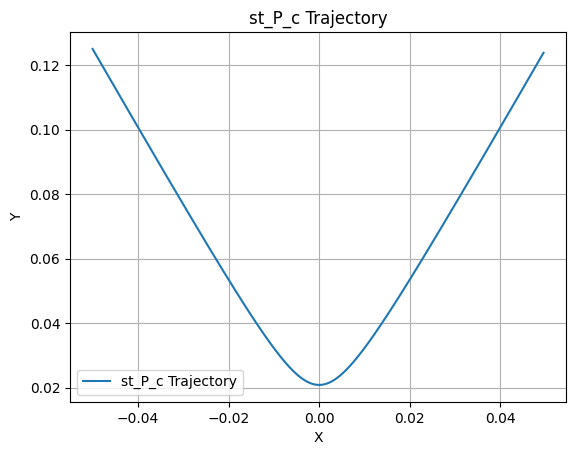

In [ ]:
import matplotlib.pyplot as plt

st_P_c = reference_joint_trajectory.GaitPlanner.st_P_c
plt.plot(st_P_c[:, 0], st_P_c[:, 1], label="st_P_c Trajectory")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("st_P_c Trajectory")
plt.legend()
plt.grid()
plt.show()

In [ ]:
st_P_c, st_V_c, t0_swing, t_swing = CalcNstepsCoMTrajectory(num_step=2,
                                                            step_length=reference_joint_trajectory.GaitPlanner.step_length,
                                                            step_time=reference_joint_trajectory.GaitPlanner.step_time,
                                                            z_com=reference_joint_trajectory.GaitPlanner.z_com,
                                                            y_0=reference_joint_trajectory.GaitPlanner.y_0,
                                                            desire_robot_height=reference_joint_trajectory.GaitPlanner.desire_torso_height)

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (3,) + inhomogeneous part.

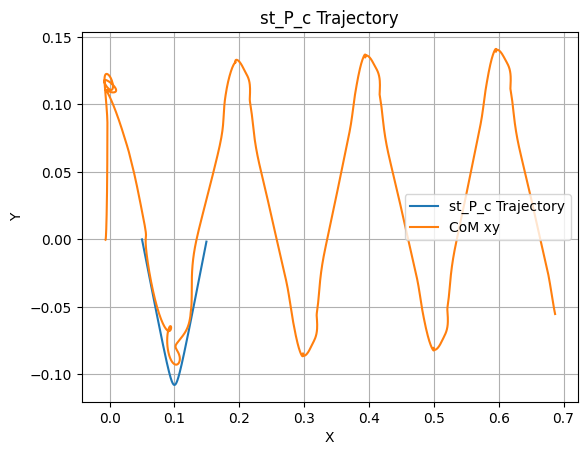

In [ ]:
plt.plot(st_P_c[:, 0]+0.1, st_P_c[:, 1]-0.125, label="st_P_c Trajectory")
plt.plot(W_P_com_x,W_P_com_y, label="CoM xy")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("st_P_c Trajectory")
plt.legend()
plt.grid()
plt.show()